# What Drives Patient Recommendations?
## Unified Group Analysis of CMS HCAHPS Hospital Patient Experience

**Group members:** Rebecca Quaye, Ketty Odero, Victoria Kutuusa

**Research question:** Which patient-experience dimensions are most important in predicting patients' willingness to recommend a hospital?

This notebook brings the group's exploratory analysis, PCA and clustering, supervised regression and classification, and practical hospital recommendations together into **one consistent analytical workflow**. It uses the cleaned hospital-level dataset (`hcahps_model_ready.csv`, 3,172 hospitals) and six patient-experience predictors.

**Consistency decision:** Earlier individual analyses used different train/test splits, cluster counts and predictor sets. For valid comparisons, this notebook uses the **same 60% training / 40% testing split (random_state=42)** for every supervised task, with stratification for classification, and the same six predictors. Five-fold cross-validation is performed on the training data only.

**Notebook outline**
1. Exploratory data analysis (D1 to D3)
2. Principal component analysis and K-means clustering (P3)
3. Regression: multiple linear regression and decision tree regression (P1)
4. Classification: logistic regression, classification tree and random forest (P2)
5. Summary of model results and cross-validation
6. Business prioritization
7. Findings, limitations, conclusions and AI-use documentation

**Run instructions:** Keep `hcahps_model_ready.csv` in the same folder as this notebook, select a Python kernel with pandas, numpy, matplotlib, seaborn, statsmodels and scikit-learn installed, then **Run All** from top to bottom.

## Setup

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Charts
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import seaborn as sns

# Statistics
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Preprocessing, PCA and clustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Model selection
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# Evaluation metrics
from sklearn.metrics import (silhouette_score, mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)

In [2]:
# The six patient-experience predictors and the two targets, used everywhere below
PREDICTORS = ["nurse_communication", "doctor_communication", "medicine_explanation",
              "discharge_information", "room_cleanliness", "night_quietness"]
TARGET = "target_recommend_pct"
HIGH = "target_high_recommend"

# Readable names for tables and charts
LABELS = {
    "nurse_communication": "Nurse Communication",
    "doctor_communication": "Doctor Communication",
    "medicine_explanation": "Medicine Explanation",
    "discharge_information": "Discharge Information",
    "room_cleanliness": "Room Cleanliness",
    "night_quietness": "Night Quietness",
    TARGET: "Recommendation %",
}

# One colour scheme for every chart: blue = high recommendation / main series, orange = lower / comparison
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
INK, MUTED, GRID, LIGHT_BLUE = "#1f2430", "#5f6470", "#e6e8ec", "#cfe0f7"
DIVERGING = LinearSegmentedColormap.from_list("orange_blue", [ORANGE, "#f4f2ee", BLUE])
SEQUENTIAL = LinearSegmentedColormap.from_list("blues", ["#f4f6f9", "#7fb0ec", "#0d366b"])
CLUSTER_ORDER = ["Higher Experience", "Moderate Experience", "Lower Experience"]
CLUSTER_COLORS = dict(zip(CLUSTER_ORDER, ["#0d366b", "#3987e5", "#9ec5f4"]))

sns.set_theme(style="whitegrid", rc={
    "figure.dpi": 110, "axes.edgecolor": GRID, "grid.color": GRID, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
})


def finish(ax, title, xlabel=None, ylabel=None, subtitle=None):
    # Title (with an optional grey subtitle line) and axis labels
    ax.set_title(title + (f"\n{subtitle}" if subtitle else ""), color=INK, pad=12)
    ax.set_xlabel(xlabel or "")
    ax.set_ylabel(ylabel or "")


def importance_chart(values, title, xlabel, as_percent=True, color=BLUE, errors=None):
    # Horizontal bars sorted from largest (top) to smallest, with value labels
    values = values.rename(index=LABELS).sort_values()
    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    shown = values * (100 if as_percent else 1)
    err = None if errors is None else errors.rename(index=LABELS).loc[values.index] * (100 if as_percent else 1)
    ax.barh(shown.index, shown.values, color=color, height=0.6, xerr=err, capsize=3,
            error_kw={"ecolor": INK, "elinewidth": 1})
    for i, v in enumerate(shown.values):
        offset = (err.values[i] if err is not None else 0) + shown.max() * 0.015
        ax.text(v + offset, i, f"{v:.1f}%" if as_percent else f"{v:.3f}", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, shown.max() * 1.18 + (err.max() if err is not None else 0))
    ax.grid(axis="y", visible=False)
    finish(ax, title, xlabel)
    plt.tight_layout()
    plt.show()


def confusion_panel(ax, cm, title):
    # Confusion matrix with counts and row percentages
    ax.imshow(cm, cmap=SEQUENTIAL)
    for i in range(2):
        for j in range(2):
            share = cm[i, j] / cm[i].sum()
            ax.text(j, i, f"{cm[i, j]}\n({share:.0%})", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() * 0.6 else INK)
    ax.set_xticks([0, 1], ["Predicted lower", "Predicted high"])
    ax.set_yticks([0, 1], ["Actual lower", "Actual high"])
    ax.grid(False)
    ax.set_title(title, color=INK, pad=10)

In [3]:
# Load the model-ready HCAHPS hospital dataset (facility IDs kept as text so leading zeros survive)
df = pd.read_csv("hcahps_model_ready.csv", dtype={"facility_id": str})

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (3172, 33)


,facility_id,facility_name,city,state,completed_surveys,response_rate_pct,cms_footnotes,flag_shorter_period,target_recommend_pct,target_high_recommend,...,item_med_side_effects,item_discharge_help,item_discharge_symptoms,census_region,log_completed_surveys,meets_300_survey_target,gap_nurse_minus_doctor,alt_outcome_rating_9_10,alt_outcome_summary_star,alt_outcome_recommend_linear
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,DOTHAN,AL,1392,17,NaN,0,79.0,1,...,45.0,83.0,90.0,South,7.238497,1,-4.0,72.0,4,91.0
1,010005,MARSHALL MEDICAL CENTERS,BOAZ,AL,745,17,NaN,0,63.0,0,...,43.0,83.0,88.0,South,6.613384,1,-4.0,68.0,3,84.0
2,010006,NORTH ALABAMA MEDICAL CENTER,FLORENCE,AL,1781,18,NaN,0,55.0,0,...,40.0,80.0,86.0,South,7.484930,1,1.0,61.0,2,80.0
3,010011,ST. VINCENT'S EAST,BIRMINGHAM,AL,1203,21,NaN,0,69.0,0,...,43.0,84.0,85.0,South,7.092574,1,-1.0,70.0,3,86.0
4,010012,DEKALB REGIONAL MEDICAL CENTER,FORT PAYNE,AL,239,14,NaN,0,59.0,0,...,45.0,86.0,89.0,South,5.476464,0,0.0,62.0,3,84.0


# 1. Exploratory Data Analysis

## 1.1 Descriptive Statistics

We first examine the descriptive statistics for the six main patient-experience measures and the hospital recommendation percentage.

In [4]:
# Mean, spread and range of the six predictors and the recommendation target
descriptive_stats = (df[PREDICTORS + [TARGET]].describe().T
                     [["count", "mean", "std", "min", "50%", "max"]]
                     .rename(columns={"50%": "median"}, index=LABELS))
descriptive_stats.round(2)

,count,mean,std,min,median,max
Nurse Communication,3172.0,78.66,5.24,52.0,79.0,98.0
Doctor Communication,3172.0,78.43,5.11,55.0,78.0,98.0
Medicine Explanation,3172.0,60.65,6.29,37.0,60.0,89.0
Discharge Information,3172.0,86.08,3.96,65.0,86.0,100.0
Room Cleanliness,3172.0,71.73,7.76,43.0,72.0,95.0
Night Quietness,3172.0,57.15,9.59,28.0,57.0,93.0
Recommendation %,3172.0,69.88,9.44,30.0,70.0,94.0


### Interpretation

The descriptive statistics show noticeable differences across the six patient-experience measures. Discharge information had the highest average score at 86.08%, followed by nurse communication (78.66%) and doctor communication (78.43%). Night quietness had the lowest average score at 57.15%, followed by medicine explanation at 60.65%. This suggests that quietness at night and communication about medicines may be areas where hospitals have more room for improvement.

The average percentage of patients who would definitely recommend their hospital was 69.88%, with a median of 70%. Recommendation rates ranged from 30% to 94%, showing considerable variation across hospitals.

## 1.2 Average Patient-Experience Scores

The average scores for the six patient-experience dimensions are compared to identify which areas receive the highest and lowest ratings across hospitals.

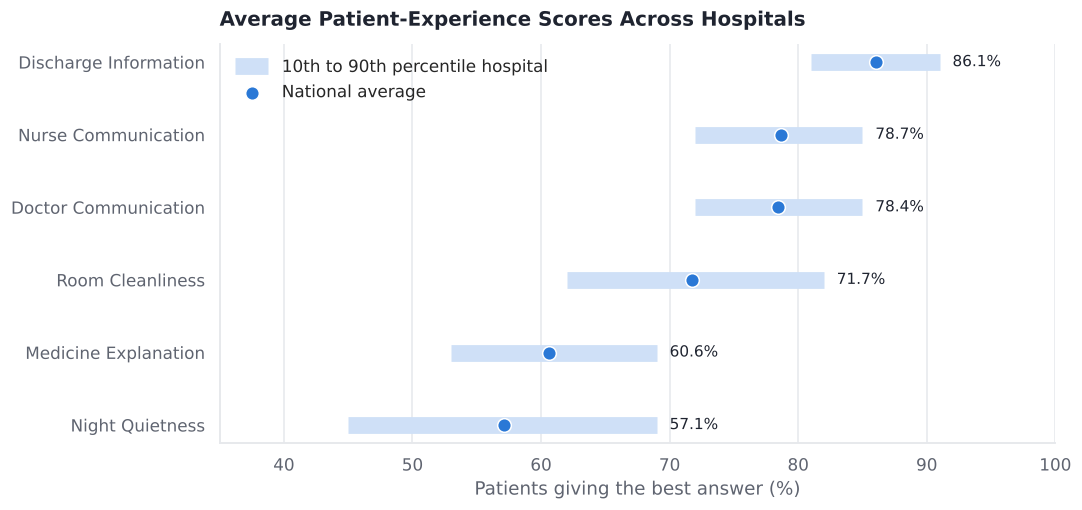

In [5]:
# National average (dot) and the spread between weaker and stronger hospitals (bar from 10th to 90th percentile)
score_summary = pd.DataFrame({
    "mean": df[PREDICTORS].mean(),
    "p10": df[PREDICTORS].quantile(0.10),
    "p90": df[PREDICTORS].quantile(0.90),
}).rename(index=LABELS).sort_values("mean")

fig, ax = plt.subplots(figsize=(10, 4.8))
rows = np.arange(len(score_summary))
ax.hlines(rows, score_summary["p10"], score_summary["p90"], color=LIGHT_BLUE, linewidth=11,
          label="10th to 90th percentile hospital")
ax.scatter(score_summary["mean"], rows, color=BLUE, s=80, zorder=3, edgecolor="white", label="National average")
for row, (_, r) in zip(rows, score_summary.iterrows()):
    ax.text(r["p90"] + 1, row, f"{r['mean']:.1f}%", va="center", fontsize=10, color=INK)
ax.set_yticks(rows, score_summary.index)
ax.set_xlim(35, 100)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", frameon=False)
finish(ax, "Average Patient-Experience Scores Across Hospitals", "Patients giving the best answer (%)")
plt.tight_layout()
plt.show()

### Interpretation

Discharge information is the highest-scoring measure (86.1%) and also the tightest: even the 10th-percentile hospital scores above 80%. Night quietness (57.1%) and medicine explanation (60.6%) are the lowest, and night quietness has the widest spread between weaker and stronger hospitals (about 45% to 70%). The measures where hospitals differ most are the ones with the most room to improve.

## 1.3 Distribution of Hospital Recommendation Percentage

The distribution of hospital recommendation percentages is examined to understand the overall pattern and variation in the continuous target variable.

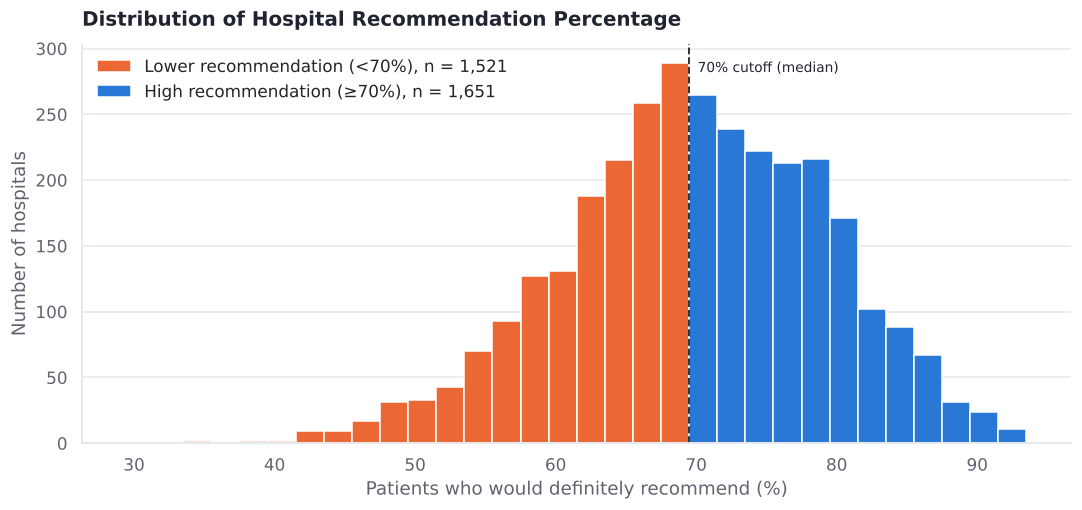

In [6]:
# Histogram of the target, coloured by the 70% cutoff used for the classification target
fig, ax = plt.subplots(figsize=(10, 4.8))
bins = np.arange(29.5, 95.5, 2)
lower, high = df.loc[df[TARGET] < 70, TARGET], df.loc[df[TARGET] >= 70, TARGET]
ax.hist(lower, bins=bins, color=ORANGE, edgecolor="white", label=f"Lower recommendation (<70%), n = {len(lower):,}")
ax.hist(high, bins=bins, color=BLUE, edgecolor="white", label=f"High recommendation (≥70%), n = {len(high):,}")
ax.axvline(69.5, color=INK, linestyle="--", linewidth=1.2)
ax.text(70.1, ax.get_ylim()[1] * 0.93, "70% cutoff (median)", color=INK, fontsize=9)
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
finish(ax, "Distribution of Hospital Recommendation Percentage",
       "Patients who would definitely recommend (%)", "Number of hospitals")
plt.tight_layout()
plt.show()

### Interpretation

Hospital recommendation percentages are mostly concentrated between 60% and 80%, with the distribution centered around 70%. The distribution is fairly mound-shaped, although there is a longer tail toward lower recommendation percentages. A few hospitals have noticeably lower recommendation rates than most hospitals.

The 70% cutoff used to classify hospitals as high recommendation is near the center of the distribution and is also the median recommendation percentage.

## 1.4 Patient Experience: High vs. Lower Recommendation Hospitals

The average patient-experience scores are compared between hospitals with high recommendation rates (70% or higher) and hospitals with lower recommendation rates (below 70%).

,Lower Recommendation (<70%),High Recommendation (≥70%),Difference
Night Quietness,53.05,60.92,7.88
Room Cleanliness,68.48,74.74,6.26
Medicine Explanation,57.41,63.63,6.21
Nurse Communication,75.74,81.34,5.60
Doctor Communication,75.70,80.95,5.25
Discharge Information,84.08,87.92,3.84


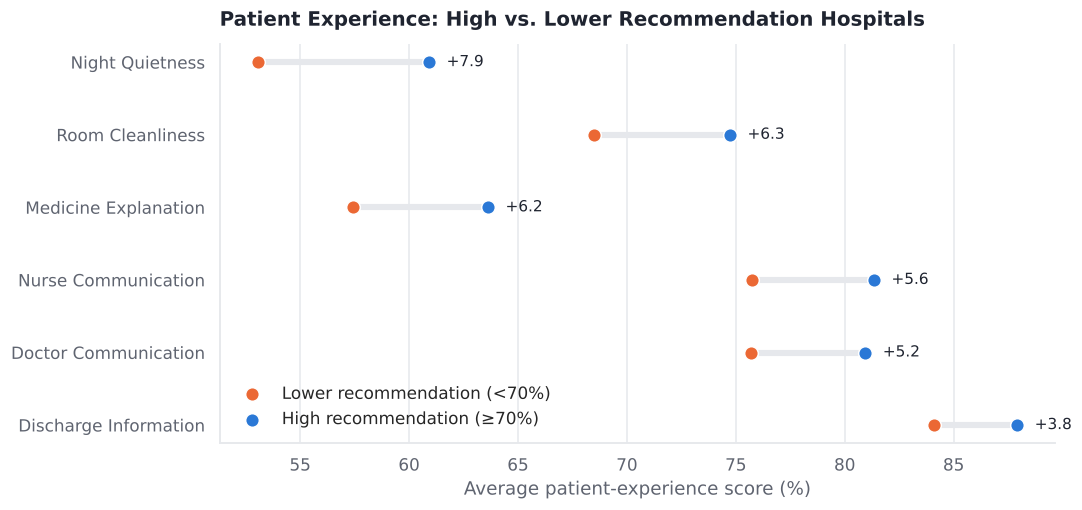

In [7]:
# Mean score of each measure in the two recommendation groups, and the difference
group_means = df.groupby(HIGH)[PREDICTORS].mean().T
group_means.columns = ["Lower Recommendation (<70%)", "High Recommendation (≥70%)"]
group_means["Difference"] = group_means["High Recommendation (≥70%)"] - group_means["Lower Recommendation (<70%)"]
group_means = group_means.sort_values("Difference", ascending=False).rename(index=LABELS)
display(group_means.round(2))

# Dumbbell chart: each line joins the two group averages; its length is the difference
plot_data = group_means.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.8))
rows = np.arange(len(plot_data))
ax.hlines(rows, plot_data.iloc[:, 0], plot_data.iloc[:, 1], color=GRID, linewidth=4)
ax.scatter(plot_data.iloc[:, 0], rows, color=ORANGE, s=80, zorder=3, edgecolor="white", label="Lower recommendation (<70%)")
ax.scatter(plot_data.iloc[:, 1], rows, color=BLUE, s=80, zorder=3, edgecolor="white", label="High recommendation (≥70%)")
for row, (_, r) in zip(rows, plot_data.iterrows()):
    ax.text(r.iloc[1] + 0.8, row, f"+{r['Difference']:.1f}", va="center", fontsize=10, color=INK)
ax.set_yticks(rows, plot_data.index)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower left")
finish(ax, "Patient Experience: High vs. Lower Recommendation Hospitals", "Average patient-experience score (%)")
plt.tight_layout()
plt.show()

### Interpretation

High-recommendation hospitals scored higher than lower-recommendation hospitals across all six patient-experience measures. The largest difference was in night quietness, where high-recommendation hospitals scored 7.88 percentage points higher. This was followed by room cleanliness (6.26 points) and medicine explanation (6.21 points).

The smallest difference was in discharge information at 3.84 percentage points. Overall, the results show clear differences in patient-experience scores between high- and lower-recommendation hospitals.

### Comparing the Differences on a Common Scale

The six measures have different spreads (for example, discharge information varies much less across hospitals than night quietness), so raw differences in percentage points are not directly comparable. **Cohen's d** divides each difference by the pooled standard deviation, putting all six measures on one scale (0.5 is a medium difference, 0.8 or more is large).

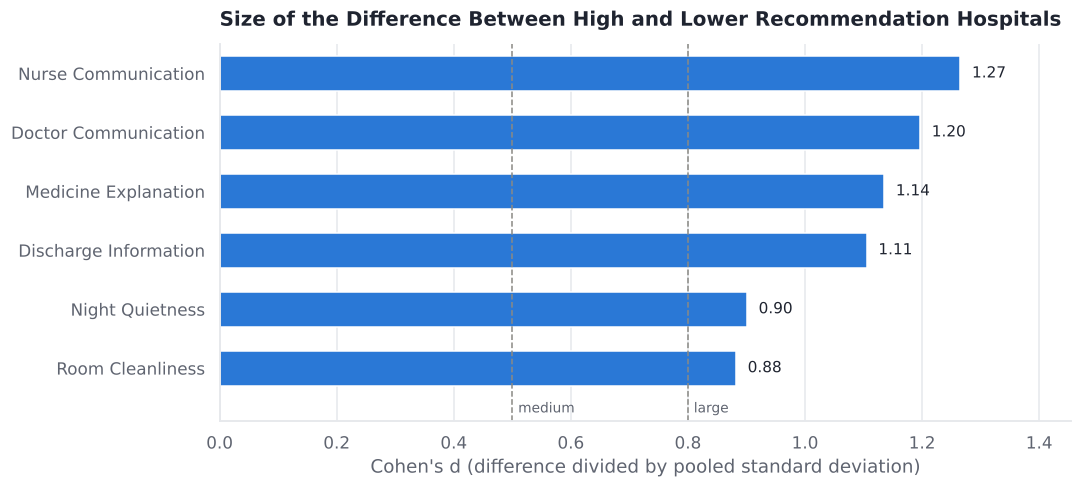

In [8]:
# Cohen's d for each measure: difference in means divided by the pooled standard deviation
high_group, lower_group = df[df[HIGH] == 1], df[df[HIGH] == 0]
cohens_d = {}
for col in PREDICTORS:
    a, b = high_group[col], lower_group[col]
    pooled_sd = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    cohens_d[col] = (a.mean() - b.mean()) / pooled_sd
cohens_d = pd.Series(cohens_d).rename(index=LABELS).sort_values()

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(cohens_d.index, cohens_d.values, color=BLUE, height=0.6)
for i, v in enumerate(cohens_d.values):
    ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=10, color=INK)
for line, name in [(0.5, "medium"), (0.8, "large")]:
    ax.axvline(line, color=GREY, linestyle="--", linewidth=1)
    ax.text(line + 0.01, -0.75, name, ha="left", fontsize=9, color=MUTED)
ax.set_xlim(0, cohens_d.max() * 1.15)
ax.set_ylim(-0.9, len(cohens_d) - 0.5)
ax.grid(axis="y", visible=False)
finish(ax, "Size of the Difference Between High and Lower Recommendation Hospitals",
       "Cohen's d (difference divided by pooled standard deviation)")
plt.tight_layout()
plt.show()

### Interpretation

On a common scale, **every difference is large** (Cohen's d between 0.88 and 1.27), so high-recommendation hospitals are better across the whole stay, not on one measure.

The ranking also changes. Night quietness and room cleanliness have the largest raw gaps (7.9 and 6.3 points) but the smallest standardized gaps (0.90 and 0.88), because those scores vary a lot across all hospitals. Nurse communication (1.27) and doctor communication (1.20) separate the two groups most clearly relative to their spread. This matches the correlation and modelling results that follow, where the communication measures carry most of the predictive weight.

## 1.5 Correlation Analysis

A correlation analysis was conducted to examine the relationships among the six patient-experience measures and hospital recommendation percentage.

,Nurse Communication,Doctor Communication,Medicine Explanation,Discharge Information,Room Cleanliness,Night Quietness,Recommendation %
Nurse Communication,1.00,0.82,0.84,0.73,0.60,0.61,0.71
Doctor Communication,0.82,1.00,0.78,0.66,0.52,0.60,0.67
Medicine Explanation,0.84,0.78,1.00,0.66,0.58,0.57,0.63
Discharge Information,0.73,0.66,0.66,1.00,0.48,0.39,0.64
Room Cleanliness,0.60,0.52,0.58,0.48,1.00,0.53,0.54
Night Quietness,0.61,0.60,0.57,0.39,0.53,1.00,0.54
Recommendation %,0.71,0.67,0.63,0.64,0.54,0.54,1.00


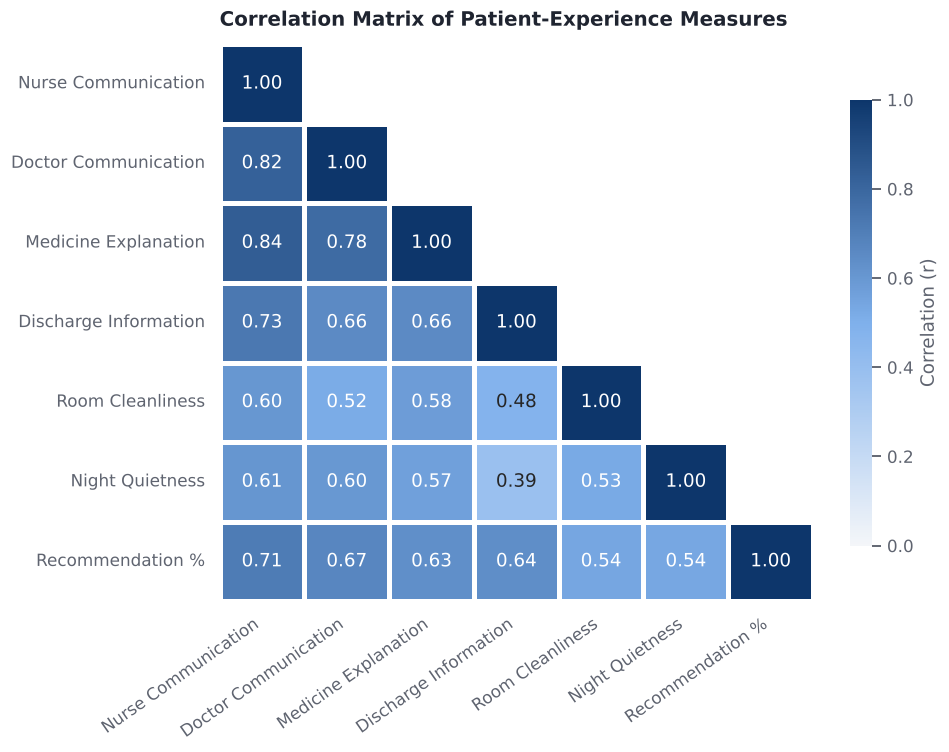

In [9]:
# Correlation matrix of the six predictors and the recommendation target
correlation_matrix = df[PREDICTORS + [TARGET]].corr().rename(index=LABELS, columns=LABELS)
display(correlation_matrix.round(2))

# Heatmap of the lower triangle (the upper triangle repeats it)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt=".2f", cmap=SEQUENTIAL, vmin=0, vmax=1,
            linewidths=2, linecolor="white", cbar_kws={"label": "Correlation (r)", "shrink": 0.8}, ax=ax)
ax.grid(False)
ax.tick_params(axis="x", rotation=35)
plt.setp(ax.get_xticklabels(), ha="right")
finish(ax, "Correlation Matrix of Patient-Experience Measures")
plt.tight_layout()
plt.show()

### Interpretation

All six measures are positively correlated with the recommendation percentage. Nurse communication has the strongest correlation (r = 0.71), followed by doctor communication (0.67), discharge information (0.64) and medicine explanation (0.63); room cleanliness and night quietness are weaker (0.54 each).

The predictors are also strongly correlated with one another, especially the three communication measures (nurse with medicine explanation r = 0.84, nurse with doctor r = 0.82). This overlap means later models may share credit between these measures unpredictably, which is checked with the variance inflation factors in the regression section.

## 1.6 Hospital Recommendation Percentage by Region

Hospital recommendation percentages are compared across U.S. Census regions to examine whether patient recommendation patterns differ geographically.

,Hospitals,Mean,Median,Std_Dev,Minimum,Maximum
census_region,,,,,,
Midwest,840,70.93,71.0,9.57,30.0,94.0
West,668,70.01,71.0,9.60,35.0,93.0
South,1176,69.83,70.0,9.06,38.0,94.0
Northeast,478,68.09,68.0,9.62,42.0,93.0
Territory,10,63.90,63.0,9.43,49.0,78.0


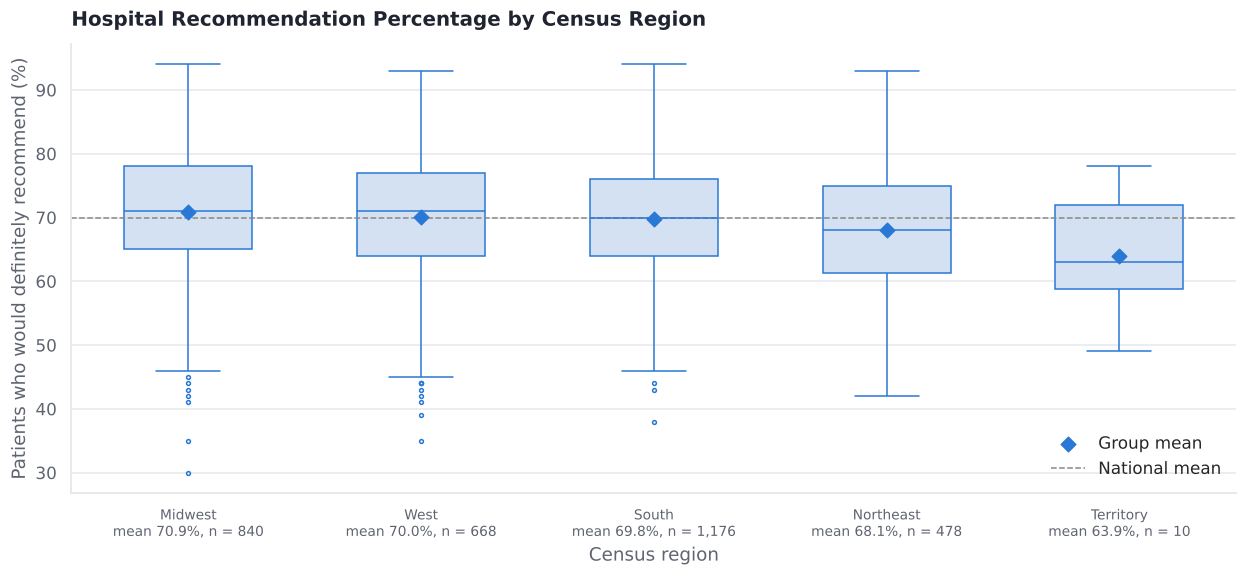

In [10]:
def recommendation_boxplot(group_col, order, title, xlabel):
    # Box plot of the recommendation rate per group, with the group mean (diamond) and the national mean (dashed)
    fig, ax = plt.subplots(figsize=(11.5, 5.4))
    sns.boxplot(data=df, x=group_col, y=TARGET, order=order, color=LIGHT_BLUE, linecolor=BLUE,
                width=0.55, fliersize=2.5, ax=ax)
    means = df.groupby(group_col)[TARGET].mean().loc[order]
    counts = df[group_col].value_counts().loc[order]
    ax.scatter(range(len(order)), means.values, marker="D", color=BLUE, s=45, zorder=3, label="Group mean")
    ax.axhline(df[TARGET].mean(), color=GREY, linestyle="--", linewidth=1, label="National mean")
    ax.set_xticks(range(len(order)), [f"{g}\nmean {m:.1f}%, n = {n:,}" for g, m, n in zip(order, means, counts)], fontsize=9)
    ax.legend(frameon=False, loc="lower right")
    finish(ax, title, xlabel, "Patients who would definitely recommend (%)")
    plt.tight_layout()
    plt.show()


# Summary statistics by Census region, ordered by mean recommendation
region_summary = (df.groupby("census_region")[TARGET]
                  .agg(Hospitals="count", Mean="mean", Median="median", Std_Dev="std", Minimum="min", Maximum="max")
                  .sort_values("Mean", ascending=False))
display(region_summary.round(2))
recommendation_boxplot("census_region", list(region_summary.index),
                       "Hospital Recommendation Percentage by Census Region", "Census region")

### Interpretation

Hospital recommendation percentages varied somewhat across Census regions. Among the four main U.S. regions, the Midwest had the highest average recommendation percentage at 70.93%, followed by the West (70.01%) and South (69.83%). The Northeast had the lowest average at 68.09%.

The Territory group had a lower average recommendation percentage of 63.90%, but it contained only 10 hospitals, so this result should be interpreted cautiously. The boxplot also shows several hospitals with unusually low recommendation percentages, particularly in the Midwest, West, and South.

## 1.7 Hospital Recommendation Percentage by Survey Volume

Hospital recommendation percentages are compared between hospitals with fewer than 300 completed surveys and hospitals with 300 or more completed surveys.

,Hospitals,Mean,Median,Std_Dev,Minimum,Maximum
survey_size_group,,,,,,
300 or More Surveys,2398,69.04,69.0,8.87,35.0,94.0
Fewer than 300 Surveys,774,72.49,73.0,10.60,30.0,94.0


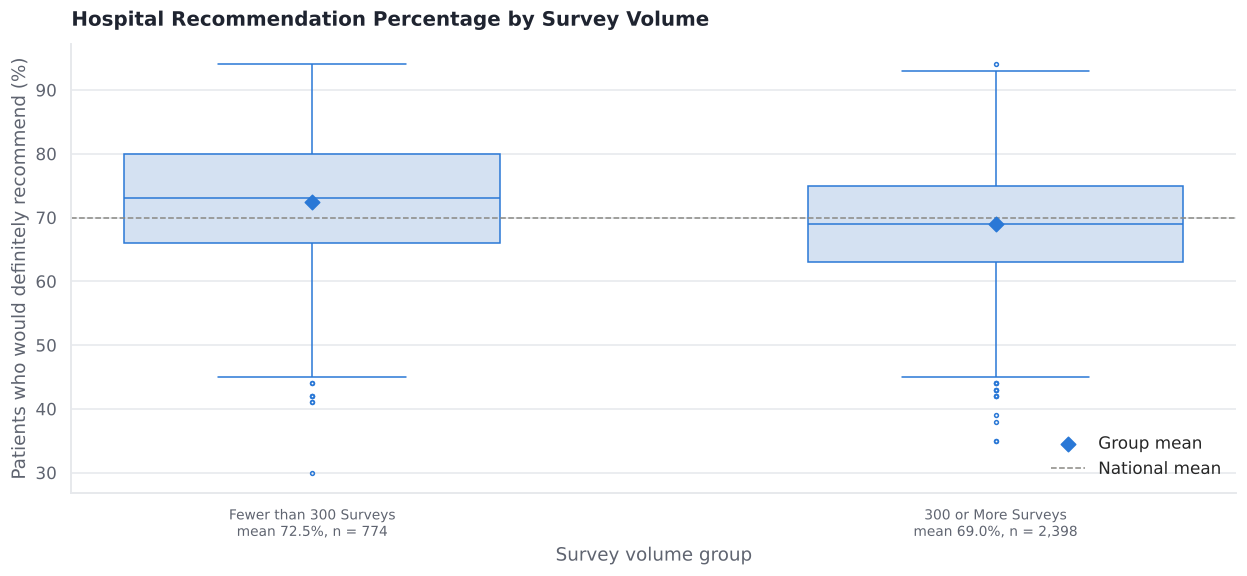

In [11]:
# Label hospitals by completed-survey volume
size_labels = {0: "Fewer than 300 Surveys", 1: "300 or More Surveys"}
df["survey_size_group"] = df["meets_300_survey_target"].map(size_labels)

# Summary statistics and box plot by survey-volume group
size_summary = df.groupby("survey_size_group")[TARGET].agg(
    Hospitals="count", Mean="mean", Median="median", Std_Dev="std", Minimum="min", Maximum="max")
display(size_summary.round(2))
recommendation_boxplot("survey_size_group", list(size_labels.values()),
                       "Hospital Recommendation Percentage by Survey Volume", "Survey volume group")

### Interpretation

Hospitals with fewer than 300 completed surveys had a higher average recommendation percentage (72.49%) than hospitals with 300 or more completed surveys (69.04%).

The median recommendation percentage was also higher for hospitals with fewer than 300 completed surveys (73%) compared with hospitals with 300 or more completed surveys (69%).

These findings suggest that hospital recommendation percentages differ between the two survey-volume groups in our dataset.

However, the number of completed surveys reflects survey volume rather than hospital size. A hospital with fewer completed surveys is not necessarily smaller than one with more completed surveys.

Therefore, these results should not be interpreted as evidence that smaller hospitals receive higher recommendation ratings.

Because our dataset does not include a reliable measure of hospital size, such as the number of staffed beds or patient capacity, we cannot determine whether recommendation percentages differ systematically between smaller and larger hospitals.

This limitation will be acknowledged in the Study Limitations section.

## 1.8 Outlier Analysis

Potential outliers were examined for the six patient-experience measures and hospital recommendation percentage using the interquartile range (IQR) method.

,Variable,Lower Bound,Upper Bound,Potential Outliers
0,Nurse Communication,64.5,92.5,38
1,Doctor Communication,64.5,92.5,32
2,Medicine Explanation,44.0,76.0,51
3,Discharge Information,76.5,96.5,72
4,Room Cleanliness,52.0,92.0,25
5,Night Quietness,31.5,83.5,18
6,Recommendation %,44.5,96.5,21


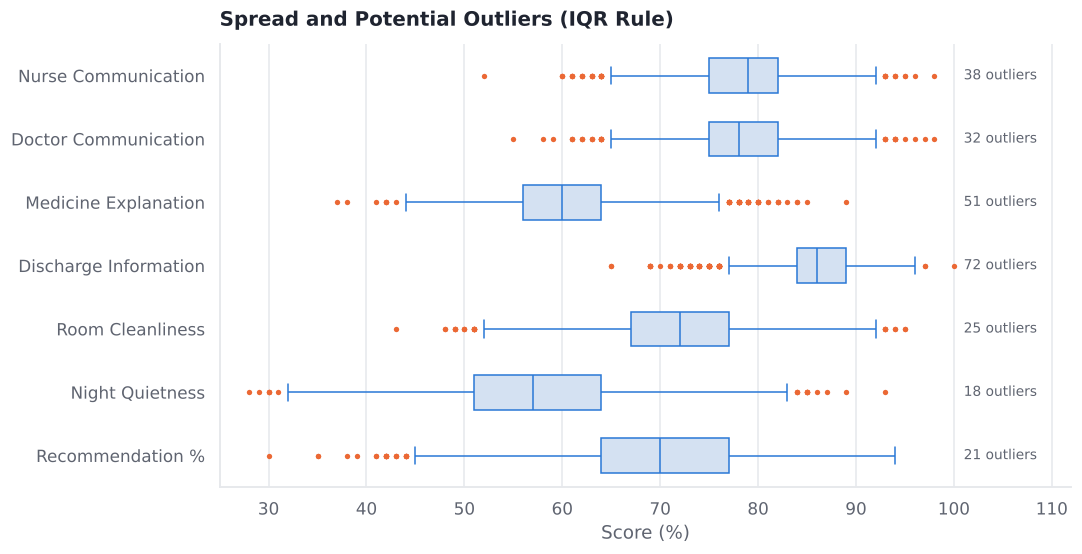

In [12]:
# Count potential outliers with the IQR rule (beyond 1.5 x IQR from the quartiles)
outlier_results = []
for variable in PREDICTORS + [TARGET]:
    q1, q3 = df[variable].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_results.append({
        "Variable": LABELS[variable], "Lower Bound": lower_bound, "Upper Bound": upper_bound,
        "Potential Outliers": int(((df[variable] < lower_bound) | (df[variable] > upper_bound)).sum()),
    })
outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(2))

# Box plots of all seven variables on the same percentage scale; outliers shown in orange
long_format = df[PREDICTORS + [TARGET]].rename(columns=LABELS).melt(var_name="Variable", value_name="Score")
fig, ax = plt.subplots(figsize=(10, 5.2))
sns.boxplot(data=long_format, y="Variable", x="Score", color=LIGHT_BLUE, linecolor=BLUE, width=0.55,
            flierprops={"marker": "o", "markerfacecolor": ORANGE, "markeredgecolor": "none", "markersize": 3.5}, ax=ax)
for i, n in enumerate(outlier_summary["Potential Outliers"]):
    ax.text(101, i, f"{n} outliers", va="center", fontsize=9, color=MUTED)
ax.set_xlim(25, 112)
finish(ax, "Spread and Potential Outliers (IQR Rule)", "Score (%)")
plt.tight_layout()
plt.show()

### Interpretation

The IQR method identified potential outliers across the patient-experience measures and recommendation percentage. Discharge information had the largest number of potential outliers (72), while night quietness had the fewest (18). The recommendation percentage had 21 potential outliers.

These observations were retained because the values remain within plausible ranges for hospital survey percentages and may represent genuine differences in patient experience across hospitals. Removing them solely because they are statistically unusual could eliminate meaningful variation in the data.

# 2. Principal Component Analysis (PCA)

PCA was performed to examine whether the six patient-experience measures could be summarized into fewer components.

The correlation analysis showed strong relationships among several communication measures, suggesting that some variables may contain overlapping information.

The six patient-experience predictors were included in PCA, while the recommendation targets were excluded.

In [13]:
# Standardize the six predictors so each contributes equally (the targets are not used)
X_pca = df[PREDICTORS].copy()
X_pca_scaled = pd.DataFrame(StandardScaler().fit_transform(X_pca), columns=PREDICTORS, index=X_pca.index)
print("PCA dataset shape:", X_pca_scaled.shape)
X_pca_scaled.head()

PCA dataset shape: (3172, 6)


,nurse_communication,doctor_communication,medicine_explanation,discharge_information,room_cleanliness,night_quietness
0,-0.507701,0.307064,-0.261848,0.231797,-0.223691,0.819231
1,-0.316733,0.502765,-0.579714,-0.020523,-0.868500,1.027853
2,-0.889635,-1.062846,-1.215445,-0.777483,-0.997462,0.714920
3,-0.125766,0.111362,-0.579714,-0.272843,-1.126424,0.401986
4,0.256168,0.307064,-0.102915,0.231797,-1.771233,0.297675


## 2.1 PCA Explained Variance

PCA was applied to the six standardized patient-experience measures to examine how much variation each principal component explains.

The explained variance ratios and cumulative explained variance were calculated to help determine the appropriate number of components to retain.

,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,69.20,69.20
1,PC2,11.05,80.25
2,PC3,8.47,88.72
3,PC4,5.44,94.15
4,PC5,3.48,97.63
5,PC6,2.37,100.00


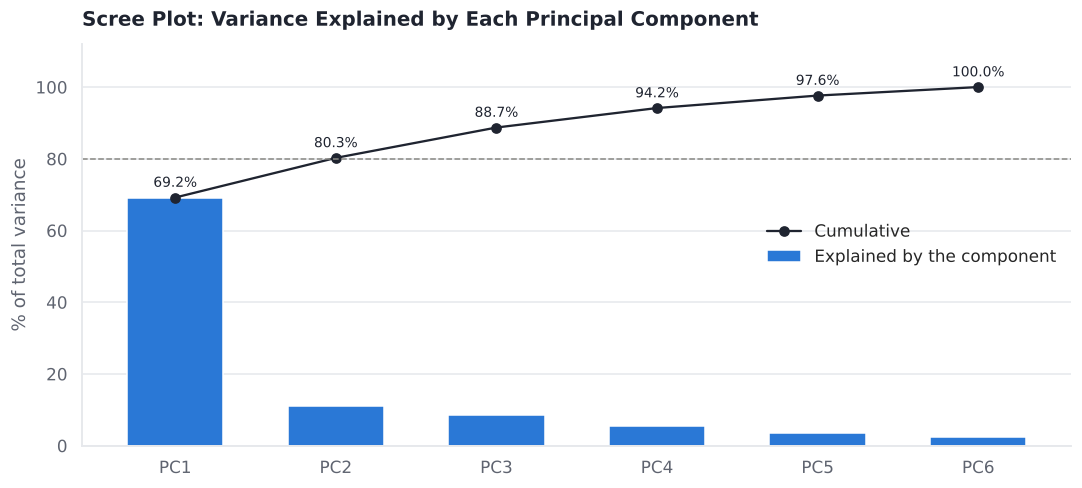

In [14]:
# Fit PCA with all six components and summarise the variance each explains
pca = PCA(n_components=6).fit(X_pca_scaled)
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
pca_summary = pd.DataFrame({
    "Principal Component": [f"PC{i}" for i in range(1, 7)],
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100,
})
display(pca_summary.round(2))

# Scree plot: bars for each component, line for the running total
fig, ax = plt.subplots(figsize=(10, 4.6))
components = np.arange(1, 7)
ax.bar(components, explained_variance * 100, color=BLUE, width=0.6, label="Explained by the component")
ax.plot(components, cumulative_variance * 100, color=INK, marker="o", linewidth=1.5, label="Cumulative")
for x, value in zip(components, cumulative_variance * 100):
    ax.text(x, value + 3, f"{value:.1f}%", ha="center", fontsize=9, color=INK)
ax.axhline(80, color=GREY, linestyle="--", linewidth=1)
ax.set_xticks(components, [f"PC{i}" for i in components])
ax.set_ylim(0, 112)
ax.legend(frameon=False, loc="center right")
ax.grid(axis="x", visible=False)
finish(ax, "Scree Plot: Variance Explained by Each Principal Component", None, "% of total variance")
plt.tight_layout()
plt.show()

## 2.2 PCA Component Loadings

The component loadings were examined to understand how the six patient-experience measures contribute to each principal component.

The analysis focuses on PC1 and PC2, which together explain 80.25% of the total variation.

,PC1,PC2
Nurse Communication,0.457,-0.153
Doctor Communication,0.436,-0.138
Medicine Explanation,0.441,-0.133
Discharge Information,0.387,-0.545
Room Cleanliness,0.359,0.453
Night Quietness,0.358,0.662


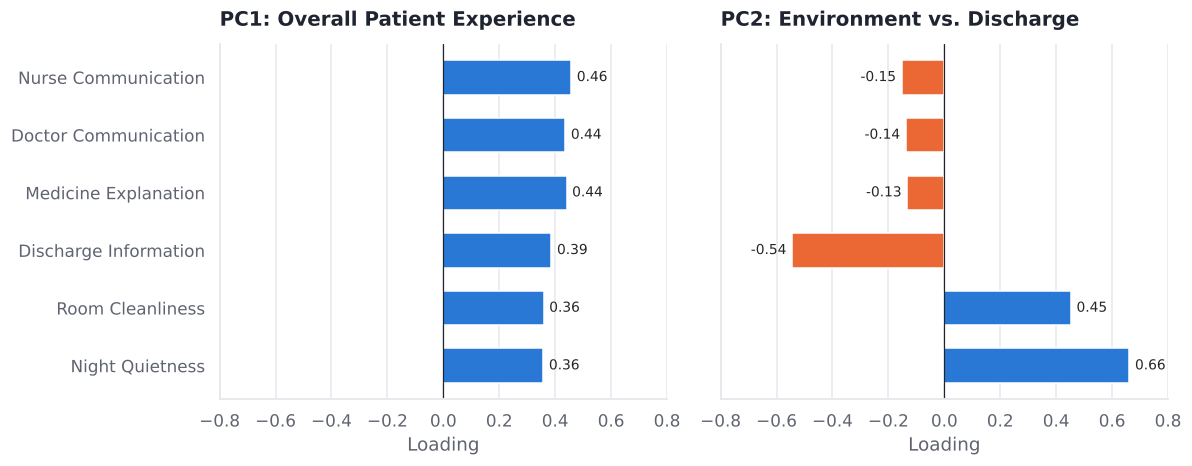

In [15]:
# Loadings of the first two components
component_loadings = pd.DataFrame(pca.components_[:2].T, columns=["PC1", "PC2"], index=PREDICTORS)
display(component_loadings.rename(index=LABELS).round(3))

# Side-by-side loading bars for PC1 and PC2
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
names = [LABELS[c] for c in PREDICTORS][::-1]
for ax, pc, title in zip(axes, ["PC1", "PC2"], ["PC1: Overall Patient Experience", "PC2: Environment vs. Discharge"]):
    values = component_loadings[pc].values[::-1]
    ax.barh(names, values, color=[BLUE if v >= 0 else ORANGE for v in values], height=0.6)
    for i, v in enumerate(values):
        ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
    ax.axvline(0, color=INK, linewidth=0.8)
    ax.set_xlim(-0.8, 0.8)
    ax.grid(axis="y", visible=False)
    finish(ax, title, "Loading")
plt.tight_layout()
plt.show()

### Interpretation of PCA Component Loadings

The PCA results suggest that the six patient-experience measures can be summarized into two main components.

**PC1 to Overall Patient Experience (69.20%)**

All six measures have positive loadings on PC1, with the strongest contributions from nurse communication (0.457), medicine explanation (0.441), and doctor communication (0.436). This suggests that PC1 represents overall patient experience, where hospitals with higher scores generally perform better across multiple dimensions.

**PC2 to Environmental Experience vs. Discharge Information (11.05%)**

PC2 has strong positive loadings for night quietness (0.662) and room cleanliness (0.453), while discharge information has a strong negative loading (-0.545). This component appears to distinguish hospitals with relatively stronger environmental experiences from those with relatively stronger discharge information scores.

Together, PC1 and PC2 explain 80.25% of the total variation in the six patient-experience measures. Based on this result, two components were retained for further analysis.

## 2.3 PCA Component Scores

The first two principal components were retained because they explain 80.25% of the total variation in the six patient-experience measures.

Component scores were calculated for each hospital to examine patient-experience patterns in a reduced two-dimensional space.

In [16]:
# Keep the first two components and compute each hospital's score on them
pca_2 = PCA(n_components=2)
pca_scores_df = pd.DataFrame(pca_2.fit_transform(X_pca_scaled),
                             columns=["PC1_Overall_Experience", "PC2_Environment_vs_Discharge"], index=df.index)
print("PCA scores shape:", pca_scores_df.shape)
pca_scores_df.head()

PCA scores shape: (3172, 2)


,PC1_Overall_Experience,PC2_Environment_vs_Discharge
0,0.088716,0.384630
1,-0.132859,0.354263
2,-1.809101,0.889105
3,-0.630217,-0.014493
4,-0.233493,-0.799068


## 2.4 PCA Visualization

The first two principal components were plotted to examine similarities and differences in patient-experience profiles across hospitals.

PC1 represents overall patient experience, while PC2 distinguishes environmental experience from discharge information. Together, these components explain 80.25% of the total variation.

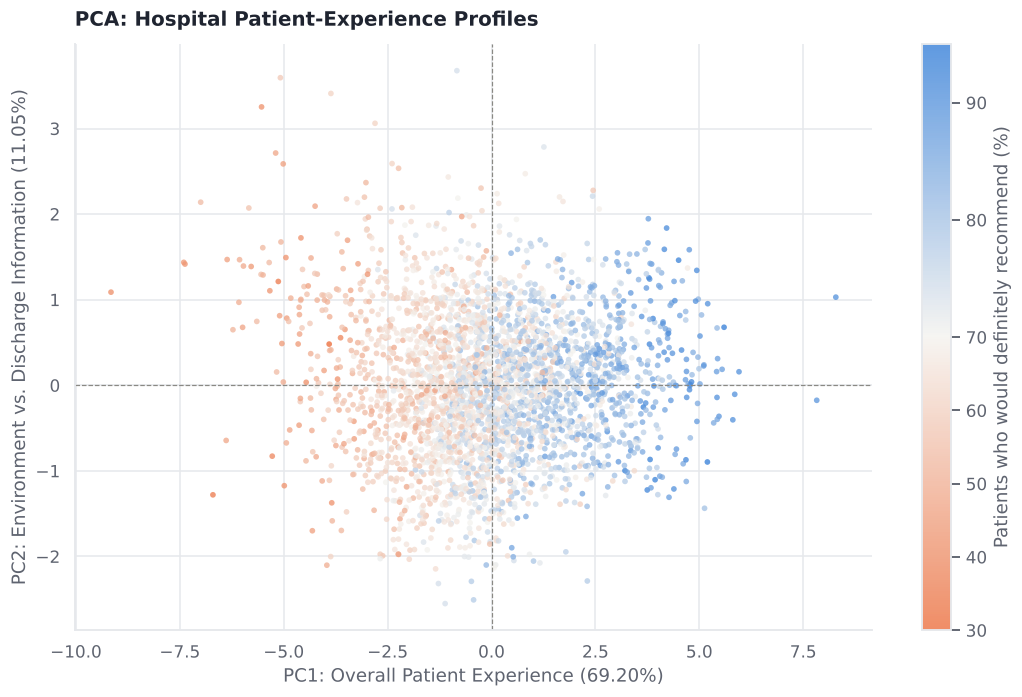

In [17]:
# Hospitals on PC1 and PC2, coloured by recommendation rate (orange below 70%, blue above)
fig, ax = plt.subplots(figsize=(10, 6.5))
points = ax.scatter(pca_scores_df["PC1_Overall_Experience"], pca_scores_df["PC2_Environment_vs_Discharge"],
                    c=df[TARGET], cmap=DIVERGING, norm=TwoSlopeNorm(vmin=30, vcenter=70, vmax=95),
                    s=14, alpha=0.75, edgecolor="none")
fig.colorbar(points, ax=ax, label="Patients who would definitely recommend (%)")
ax.axhline(0, color=GREY, linestyle="--", linewidth=0.8)
ax.axvline(0, color=GREY, linestyle="--", linewidth=0.8)
finish(ax, "PCA: Hospital Patient-Experience Profiles",
       f"PC1: Overall Patient Experience ({explained_variance[0]:.2%})",
       f"PC2: Environment vs. Discharge Information ({explained_variance[1]:.2%})")
plt.tight_layout()
plt.show()

### Interpretation of PCA Scatterplot

The PCA scatterplot shows that most hospitals are concentrated near the center, suggesting that many have similar patient-experience profiles.

The wider spread along PC1 indicates greater variation in overall patient experience, while PC2 captures differences between environmental measures and discharge information.

A few hospitals are positioned farther from the center, indicating potentially unusual patient-experience profiles.

There are no clearly separated groups in the scatterplot. However, K-means clustering may help identify meaningful hospital segments based on similarities in their patient-experience scores.

Colouring each hospital by its recommendation percentage shows that the recommendation rate changes mainly from left to right: hospitals on the negative side of PC1 are mostly orange (below 70%) and those on the positive side are mostly blue. Vertical position (PC2) shows little colour pattern, so the overall level of patient experience, rather than the balance between environment and discharge information, is what lines up with recommendation.

# 3. K-Means Clustering

K-means clustering was used to explore whether hospitals could be grouped into distinct patient-experience profiles.

The first two principal components, which explain 80.25% of the total variation, were used as inputs for clustering.

The Elbow Method was applied to help determine an appropriate number of clusters.

,0,1,2,3,4,5,6,7,8
Number of Clusters,2.0000,3.0000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000
Silhouette Score,0.4457,0.3894,0.3531,0.3476,0.3385,0.3268,0.3249,0.3244,0.3231


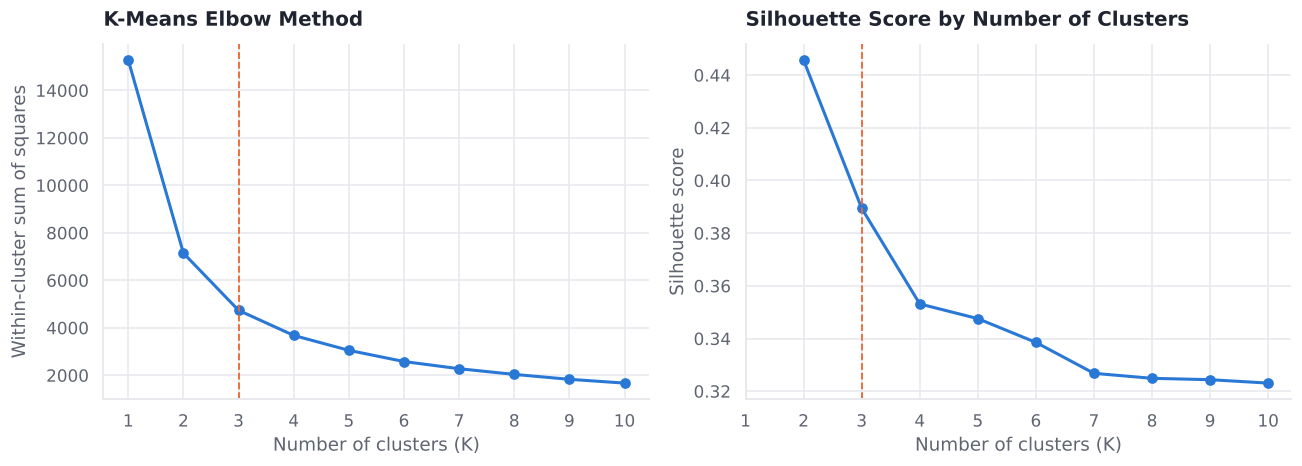

In [18]:
# Within-cluster sum of squares (elbow) for K = 1 to 10 and silhouette score for K = 2 to 10
inertia_values, silhouette_values = [], []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(pca_scores_df)
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(pca_scores_df, kmeans.labels_) if k > 1 else np.nan)

silhouette_summary = pd.DataFrame({"Number of Clusters": list(k_values)[1:], "Silhouette Score": silhouette_values[1:]})
display(silhouette_summary.round(4).T)

# Elbow and silhouette side by side, with the chosen K = 3 marked
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(list(k_values), inertia_values, marker="o", color=BLUE, linewidth=2)
finish(axes[0], "K-Means Elbow Method", "Number of clusters (K)", "Within-cluster sum of squares")
axes[1].plot(list(k_values)[1:], silhouette_values[1:], marker="o", color=BLUE, linewidth=2)
finish(axes[1], "Silhouette Score by Number of Clusters", "Number of clusters (K)", "Silhouette score")
for ax in axes:
    ax.axvline(3, color=ORANGE, linestyle="--", linewidth=1.2)
    ax.set_xticks(list(k_values))
plt.tight_layout()
plt.show()

### Interpretation of the Elbow and Silhouette Charts

The elbow plot shows a substantial decrease in within-cluster sum of squares (WCSS) as the number of clusters increases from 1 to 3.

After approximately K = 3 or K = 4, the curve begins to flatten, suggesting diminishing improvements from adding more clusters.

Based on the elbow method, three or four clusters appear reasonable. Silhouette scores will be examined to help determine which solution provides better cluster separation.

### Selection of the Number of Clusters

The elbow chart flattens after K = 3. On the silhouette chart, the two-cluster solution has the highest score (0.4457), followed by K = 3 (0.3894) and K = 4 (0.3531); scores keep falling after that.

K = 2 separates hospitals most cleanly, but it only splits them into "above" and "below" average, which repeats the binary classification target. **K = 3** was selected because it is the elbow point, has the best silhouette score of the solutions with more than two groups, and adds a useful middle tier for comparing hospitals.

All silhouette scores are moderate (below 0.5), so the clusters overlap: hospitals form a continuum rather than completely separate types.

## 3.1 Final K-Means Clustering Model

K-means clustering was performed using the first two principal components, which explain 80.25% of the total variation in the six patient-experience measures.

Three clusters were selected based on the elbow method and silhouette score comparison.

Each hospital was assigned to a cluster based on similarities in its patient-experience profile.

In [19]:
# Fit the final three-cluster model on the two retained components
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans_final.fit_predict(pca_scores_df)
pca_scores_df["Cluster"] = df["Cluster"]

# Name each cluster by its average recommendation rate (highest = Higher Experience)
cluster_rank = df.groupby("Cluster")[TARGET].mean().sort_values(ascending=False).index
CLUSTER_NAMES = dict(zip(cluster_rank, CLUSTER_ORDER))
df["Cluster Name"] = df["Cluster"].map(CLUSTER_NAMES)
pca_scores_df["Cluster Name"] = df["Cluster Name"]

df.groupby(["Cluster", "Cluster Name"]).size().rename("Hospitals").to_frame()

,,Hospitals
Cluster,Cluster Name,
0,Higher Experience,808
1,Moderate Experience,1585
2,Lower Experience,779


## 3.2 Cluster Profile Analysis

The three clusters were compared using the six original patient-experience measures.

Average scores were calculated for each cluster to identify differences in patient-experience profiles and determine the relative strengths and weaknesses of each hospital group.

In [20]:
# Average score of each measure, recommendation rate and size of each cluster
cluster_profiles = df.groupby("Cluster Name")[PREDICTORS].mean().loc[CLUSTER_ORDER]
cluster_profiles["Recommendation (%)"] = df.groupby("Cluster Name")[TARGET].mean().loc[CLUSTER_ORDER]
cluster_profiles["Hospitals"] = df["Cluster Name"].value_counts().loc[CLUSTER_ORDER]
cluster_profiles.insert(0, "Cluster", [int(k) for k in df.groupby("Cluster Name")["Cluster"].first().loc[CLUSTER_ORDER]])
cluster_profiles = cluster_profiles.rename(columns=LABELS)
cluster_profiles.round(2)

,Cluster,Nurse Communication,Doctor Communication,Medicine Explanation,Discharge Information,Room Cleanliness,Night Quietness,Recommendation (%),Hospitals
Cluster Name,,,,,,,,,
Higher Experience,0,84.77,84.23,68.23,89.62,79.44,66.60,78.25,808
Moderate Experience,1,78.56,78.24,60.08,86.36,71.22,56.31,70.22,1585
Lower Experience,2,72.53,72.81,53.94,81.84,64.78,49.04,60.51,779


### Interpretation of Hospital Clusters

K-means clustering identified three hospital groups with different levels of patient-experience performance.

**Cluster 0 to High Patient Experience (808 hospitals)**

Hospitals in this cluster had the highest average scores across all six patient-experience measures. Their average recommendation percentage was 78.25%, the highest among the three groups.

**Cluster 1 to Moderate Patient Experience (1,585 hospitals)**

This was the largest cluster, with patient-experience scores generally falling between Clusters 0 and 2. Its average recommendation percentage was 70.22%. Night quietness and medicine explanation were among its lowest-scoring measures.

**Cluster 2 to Lower Patient Experience (779 hospitals)**

Hospitals in this cluster had the lowest average scores across all six measures. Night quietness (49.04%) and medicine explanation (53.94%) were particularly low. This cluster also had the lowest average recommendation percentage at 60.51%.

Overall, the clusters primarily distinguish hospitals by their general patient-experience performance. The difference in average recommendation percentage between the highest- and lowest-performing clusters was 17.74 percentage points.

These findings suggest that hospitals with stronger patient-experience profiles also tend to have higher recommendation percentages. However, the results are descriptive and do not establish causal relationships.

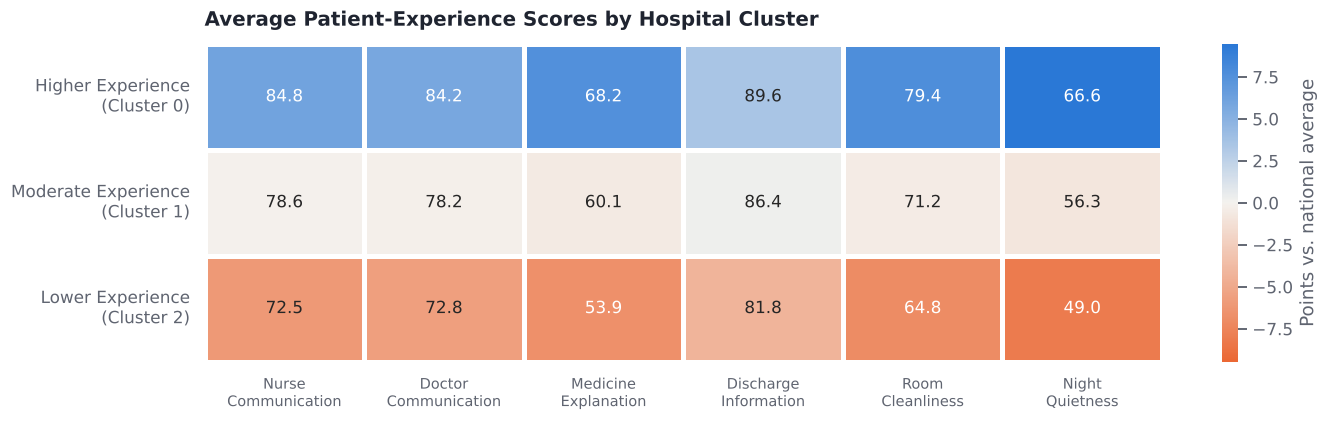

In [21]:
# Heatmap: cell text is the cluster's average score; colour shows points above (blue) or below (orange) the national average
scores = cluster_profiles[[LABELS[c] for c in PREDICTORS]]
difference = scores - df[PREDICTORS].mean().rename(index=LABELS)
limit = np.abs(difference.values).max()
fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(difference, annot=scores.round(1), fmt="", cmap=DIVERGING, vmin=-limit, vmax=limit,
            linewidths=2, linecolor="white", annot_kws={"fontsize": 11},
            cbar_kws={"label": "Points vs. national average"}, ax=ax)
ax.set_yticklabels([f"{name}\n(Cluster {c})" for name, c in zip(scores.index, cluster_profiles["Cluster"])], rotation=0)
ax.set_xticklabels([LABELS[c].replace(" ", "\n") for c in PREDICTORS], rotation=0, fontsize=9.5)
finish(ax, "Average Patient-Experience Scores by Hospital Cluster")
plt.tight_layout()
plt.show()

### Interpretation of Cluster Heatmap

The heatmap shows clear differences in patient-experience scores across the three hospital clusters.

Cluster 0 consistently has the highest scores across all six measures, while Cluster 1 shows moderate performance and Cluster 2 has the lowest scores.

Discharge information is the highest-scoring measure in all three clusters, while night quietness and medicine explanation have the lowest scores.

Overall, the clusters primarily reflect different levels of patient-experience performance rather than completely different patterns of strengths and weaknesses.

## 3.3 Recommendation Rates by Cluster

The recommendation rate was **not** used to form the clusters. Comparing it across the clusters afterwards shows whether the patient-experience groups also differ in how often patients would recommend the hospital.

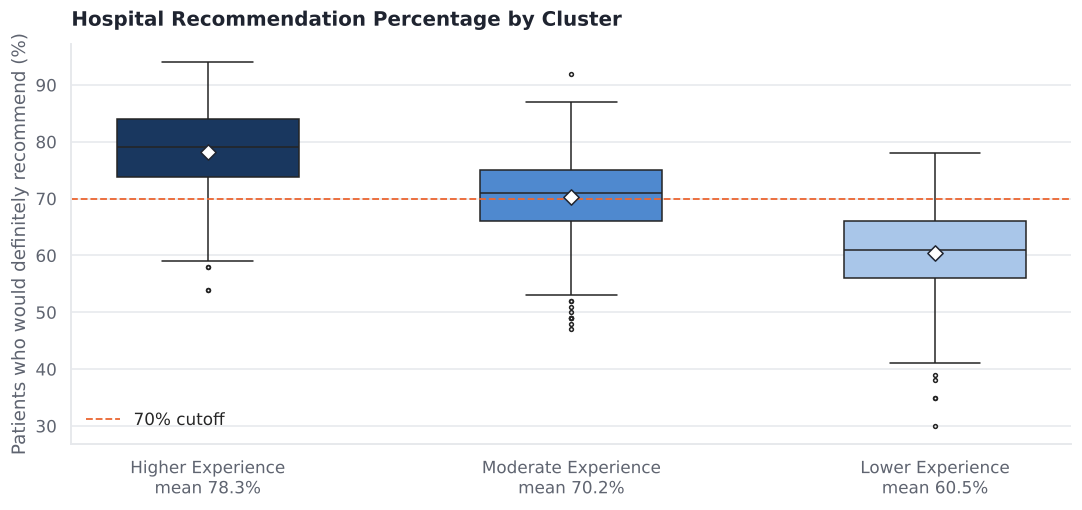

In [22]:
# Recommendation rate by cluster, with each cluster's mean marked
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.boxplot(data=df, x="Cluster Name", y=TARGET, order=CLUSTER_ORDER, hue="Cluster Name", palette=CLUSTER_COLORS,
            legend=False, width=0.5, fliersize=2.5, ax=ax)
means = df.groupby("Cluster Name")[TARGET].mean().loc[CLUSTER_ORDER]
ax.scatter(range(3), means.values, marker="D", color="white", edgecolor=INK, s=50, zorder=3)
ax.axhline(70, color=ORANGE, linestyle="--", linewidth=1.2, label="70% cutoff")
ax.set_xticks(range(3), [f"{n}\nmean {m:.1f}%" for n, m in zip(CLUSTER_ORDER, means)])
ax.legend(frameon=False, loc="lower left")
finish(ax, "Hospital Recommendation Percentage by Cluster", None, "Patients who would definitely recommend (%)")
plt.tight_layout()
plt.show()

### Interpretation

Recommendation rates step down clearly across the three clusters: 78.3% in the Higher Experience cluster, 70.2% in the Moderate cluster and 60.5% in the Lower cluster. Most Higher Experience hospitals are above the 70% cutoff and most Lower Experience hospitals are below it, while the Moderate cluster sits on the cutoff.

Because the recommendation rate was not used to build the clusters, this confirms that the patient-experience groups found from the six measures also differ in the outcome hospitals care about. The boxes still overlap, so cluster membership alone does not determine a hospital's recommendation rate.

## 3.4 Visualization of K-Means Clusters

The three hospital clusters were visualized using the first two principal components.

The scatterplot illustrates how hospitals were grouped based on similarities in their patient-experience profiles.

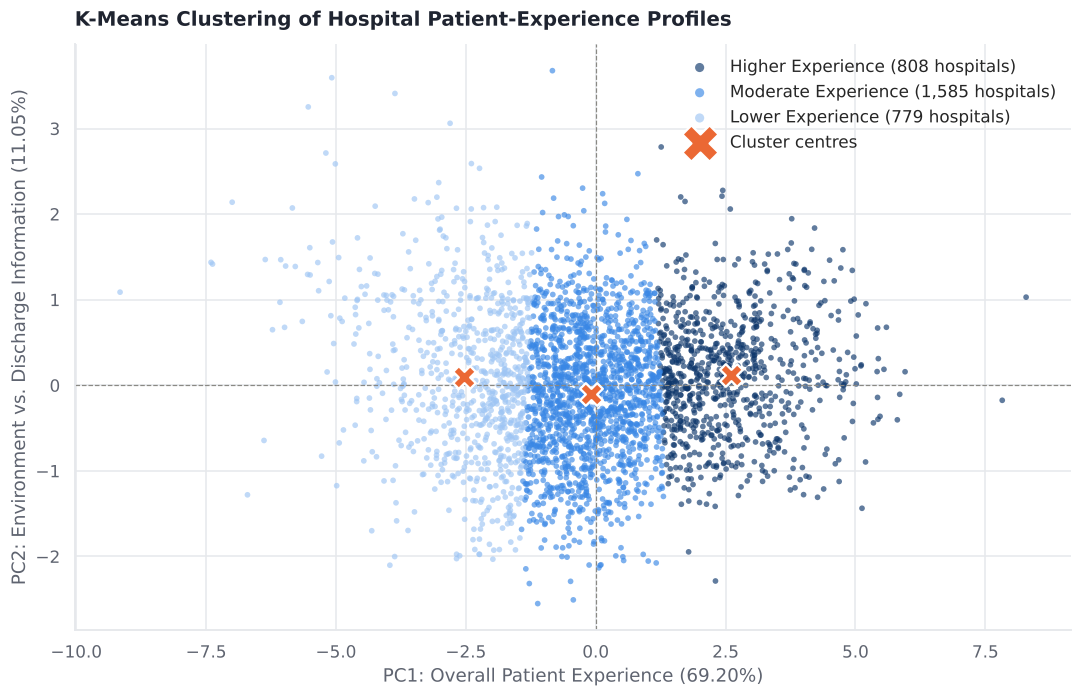

In [23]:
# The three clusters on PC1 and PC2, with the cluster centres
fig, ax = plt.subplots(figsize=(10, 6.5))
for name in CLUSTER_ORDER:
    part = pca_scores_df[pca_scores_df["Cluster Name"] == name]
    ax.scatter(part["PC1_Overall_Experience"], part["PC2_Environment_vs_Discharge"], s=14, alpha=0.65,
               color=CLUSTER_COLORS[name], edgecolor="none", label=f"{name} ({len(part):,} hospitals)")
ax.scatter(kmeans_final.cluster_centers_[:, 0], kmeans_final.cluster_centers_[:, 1], marker="X", s=220,
           color=ORANGE, edgecolor="white", linewidth=1.5, label="Cluster centres", zorder=3)
ax.axhline(0, color=GREY, linestyle="--", linewidth=0.8)
ax.axvline(0, color=GREY, linestyle="--", linewidth=0.8)
ax.legend(frameon=False, markerscale=1.6)
finish(ax, "K-Means Clustering of Hospital Patient-Experience Profiles",
       f"PC1: Overall Patient Experience ({explained_variance[0]:.2%})",
       f"PC2: Environment vs. Discharge Information ({explained_variance[1]:.2%})")
plt.tight_layout()
plt.show()

### Interpretation of K-Means Cluster Visualization

The PCA scatterplot shows three hospital clusters primarily separated along PC1, which represents overall patient experience.

Cluster 0 is concentrated on the positive side of PC1 and represents hospitals with relatively high patient-experience scores. Cluster 1 is concentrated near the center and represents moderate patient experience, while Cluster 2 is located mainly on the negative side and represents lower patient experience.

The clusters are separated more strongly along PC1 than PC2, suggesting that overall patient-experience performance is the main dimension distinguishing the groups.

These findings are consistent with the cluster profile analysis, where average recommendation percentages were 78.25%, 70.22%, and 60.51% for Clusters 0, 1, and 2, respectively.

Although K-means identifies three useful hospital segments, the moderate silhouette score (0.3894) suggests that the underlying patient-experience profiles are not strongly separated.

# 4. Supervised Learning: Multiple Linear Regression

Multiple linear regression was used to predict hospital recommendation percentage based on six patient-experience measures.

The predictors include nurse communication, doctor communication, medicine explanation, discharge information, room cleanliness, and night quietness.

The dataset was divided into 60% training and 40% testing observations, following the project proposal. Model performance will be evaluated using RMSE, MAE, and R².

In [24]:
# Predictors and continuous target, split 60% training / 40% testing
X = df[PREDICTORS].copy()
y = df[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.40, random_state=42)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 1903
Testing observations: 1269


,Predictor,Coefficient
0,Intercept,-55.3800
1,Nurse Communication,0.5097
2,Doctor Communication,0.3420
3,Medicine Explanation,-0.0592
4,Discharge Information,0.4933
5,Room Cleanliness,0.1602
6,Night Quietness,0.1385


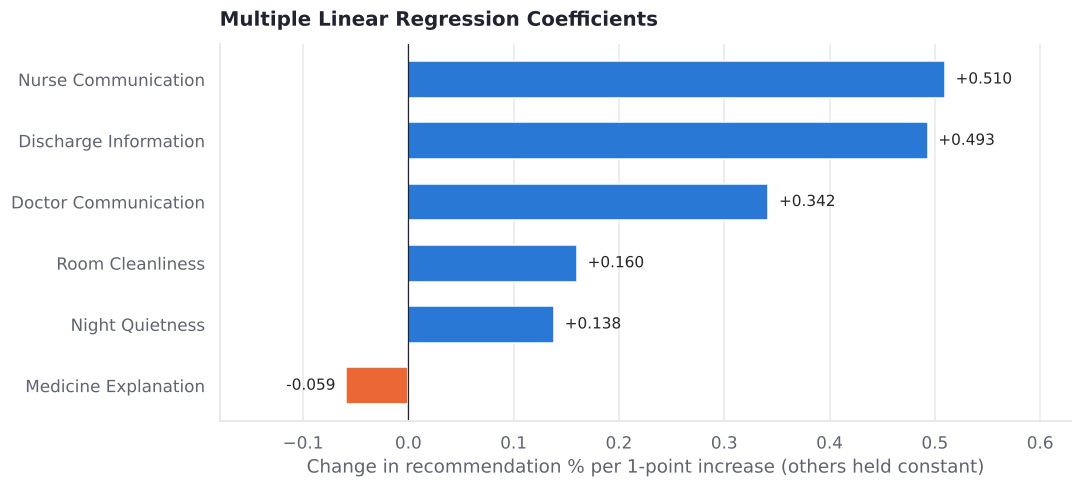

In [25]:
# Fit multiple linear regression on the training data
linear_model = LinearRegression().fit(X_train, y_train)

# Coefficient table (points of recommendation per 1-point increase, others held constant)
regression_coefficients = pd.DataFrame({
    "Predictor": ["Intercept"] + [LABELS[c] for c in PREDICTORS],
    "Coefficient": [linear_model.intercept_] + list(linear_model.coef_),
})
display(regression_coefficients.round(4))

# Coefficient chart for the six predictors
coefs = pd.Series(linear_model.coef_, index=[LABELS[c] for c in PREDICTORS]).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(coefs.index, coefs.values, color=[BLUE if v > 0 else ORANGE for v in coefs.values], height=0.6)
for i, v in enumerate(coefs.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=10)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlim(coefs.min() - 0.12, coefs.max() + 0.12)
ax.grid(axis="y", visible=False)
finish(ax, "Multiple Linear Regression Coefficients",
       "Change in recommendation % per 1-point increase (others held constant)")
plt.tight_layout()
plt.show()

### Interpretation of Multiple Linear Regression Coefficients

The regression results show that five of the six patient-experience measures have positive coefficients.

Nurse communication (0.5097) and discharge information (0.4933) have the largest positive coefficients. Holding the other predictors constant, a one-percentage-point increase in these measures is associated with approximately 0.51 and 0.49 percentage-point increases in predicted hospital recommendations, respectively.

Doctor communication (0.3420), room cleanliness (0.1602), and night quietness (0.1385) also show positive associations with recommendation percentage.

Medicine explanation has a small negative coefficient (-0.0592). However, this should be interpreted cautiously because several patient-experience measures are strongly correlated, potentially affecting the stability of the regression coefficients.

Overall, the results suggest that communication and discharge-related measures are important predictors of hospital recommendations. However, further analysis of multicollinearity and model performance is needed before drawing conclusions about their relative importance.

These relationships are associations and should not be interpreted as causal effects.

,Predictor,VIF
0,Nurse Communication,5.56
1,Doctor Communication,3.70
2,Medicine Explanation,4.01
3,Discharge Information,2.33
4,Room Cleanliness,1.74
5,Night Quietness,1.83


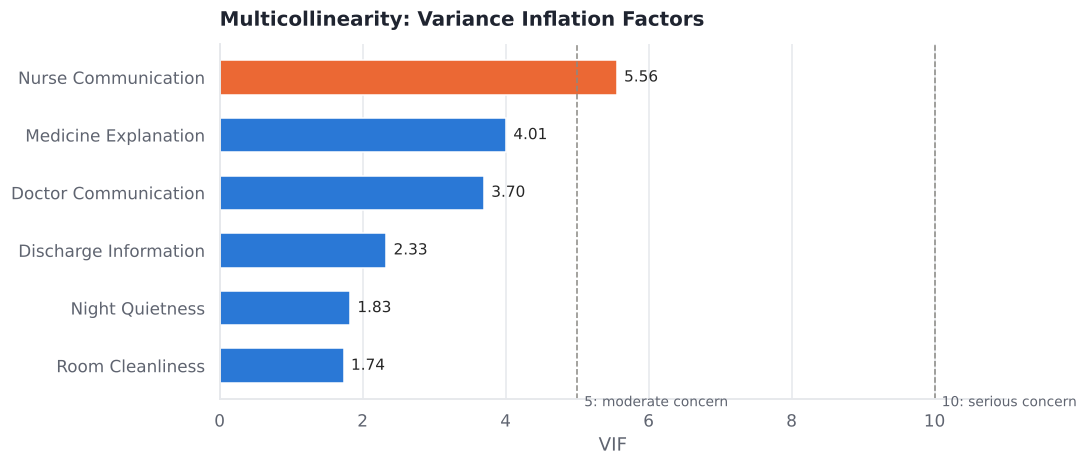

In [26]:
# Variance inflation factors on the training predictors
X_vif = sm.add_constant(X_train)
vif_table = pd.DataFrame({
    "Predictor": [LABELS[c] for c in PREDICTORS],
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
})
display(vif_table.round(2))

# VIF chart with the usual warning (5) and serious (10) thresholds
vif_sorted = vif_table.sort_values("VIF")
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.barh(vif_sorted["Predictor"], vif_sorted["VIF"], color=[ORANGE if v > 5 else BLUE for v in vif_sorted["VIF"]], height=0.6)
for i, v in enumerate(vif_sorted["VIF"]):
    ax.text(v + 0.1, i, f"{v:.2f}", va="center", fontsize=10)
for line, name in [(5, "5: moderate concern"), (10, "10: serious concern")]:
    ax.axvline(line, color=GREY, linestyle="--", linewidth=1)
    ax.text(line + 0.1, -0.7, name, fontsize=9, color=MUTED)
ax.set_xlim(0, 11)
ax.grid(axis="y", visible=False)
finish(ax, "Multicollinearity: Variance Inflation Factors", "VIF")
plt.tight_layout()
plt.show()

### Multicollinearity Assessment

Variance Inflation Factor (VIF) was calculated to assess multicollinearity among the six patient-experience predictors.

Nurse communication had the highest VIF (5.56), followed by medicine explanation (4.01) and doctor communication (3.70). These results indicate some overlap among the communication-related measures.

Discharge information (2.33), night quietness (1.83), and room cleanliness (1.74) showed relatively low multicollinearity.

The negative regression coefficient for medicine explanation may partly reflect its overlap with other communication measures, although VIF alone cannot confirm this explanation.

Since none of the VIF values exceeded 10, all six predictors were retained in the initial regression model. However, the coefficient estimates, particularly for nurse communication and medicine explanation, should be interpreted cautiously.

In [27]:
# Training and testing performance of the linear model
y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)
regression_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "RMSE": [np.sqrt(mean_squared_error(y_train, y_train_pred)), np.sqrt(mean_squared_error(y_test, y_test_pred))],
    "MAE": [mean_absolute_error(y_train, y_train_pred), mean_absolute_error(y_test, y_test_pred)],
    "R²": [r2_score(y_train, y_train_pred), r2_score(y_test, y_test_pred)],
})
regression_results.round(4)

,Dataset,RMSE,MAE,R²
0,Training,6.0643,4.9342,0.5911
1,Testing,6.2242,5.0115,0.5581


### Multiple Linear Regression Model Performance

The multiple linear regression model demonstrated moderate predictive performance on the testing dataset.

The training R² was 0.5911, while the testing R² was 0.5581. This indicates that the model explained approximately 55.81% of the variation in hospital recommendation percentages among unseen hospitals.

The testing RMSE was 6.2242 percentage points, while the testing MAE was 5.0115 percentage points. This means the model's predictions differed from actual recommendation percentages by approximately 5.01 percentage points on average.

The relatively small difference between training and testing performance suggests that the model generalizes reasonably well, with no strong evidence of overfitting.

Overall, the six patient-experience measures provide useful predictive information, although a substantial portion of the variation in hospital recommendations remains unexplained.

These results establish a baseline for comparison with the regression tree model.

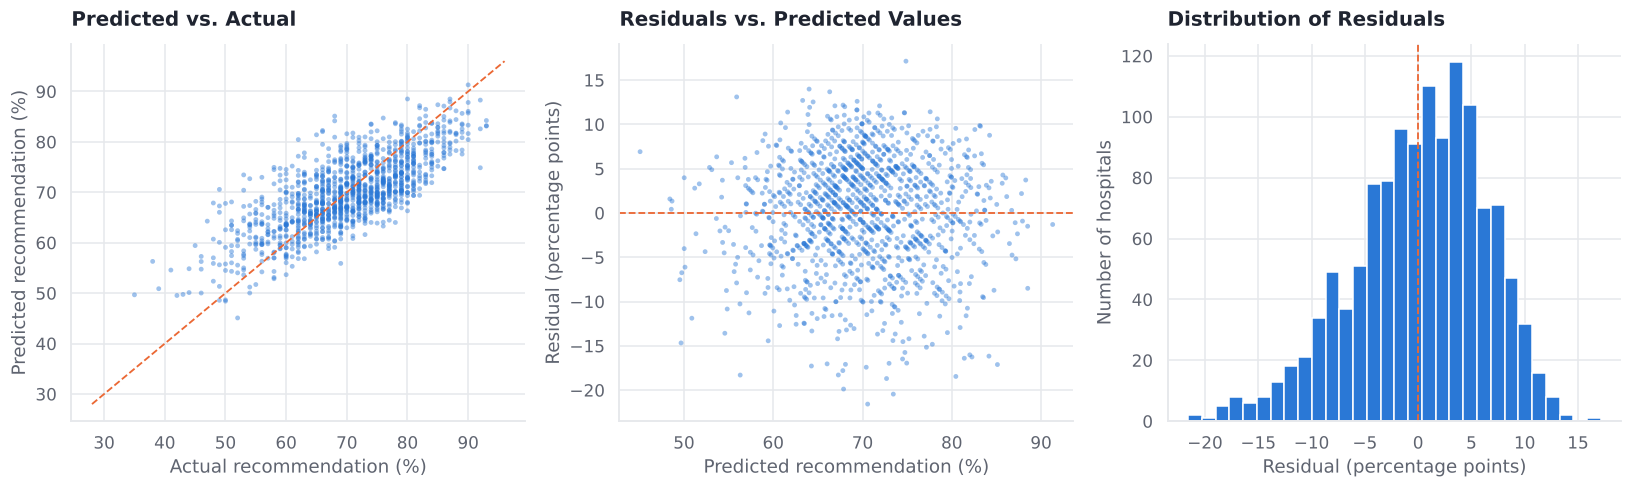

In [28]:
# Residual diagnostics on the testing data
test_residuals = y_test - y_test_pred
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

# Predicted against actual: points near the diagonal are accurate predictions
axes[0].scatter(y_test, y_test_pred, s=10, alpha=0.45, color=BLUE, edgecolor="none")
axes[0].plot([28, 96], [28, 96], color=ORANGE, linestyle="--", linewidth=1.2)
finish(axes[0], "Predicted vs. Actual", "Actual recommendation (%)", "Predicted recommendation (%)")

# Residuals against predicted values: a shapeless band around zero is the goal
axes[1].scatter(y_test_pred, test_residuals, s=10, alpha=0.45, color=BLUE, edgecolor="none")
axes[1].axhline(0, color=ORANGE, linestyle="--", linewidth=1.2)
finish(axes[1], "Residuals vs. Predicted Values", "Predicted recommendation (%)", "Residual (percentage points)")

# Distribution of residuals
axes[2].hist(test_residuals, bins=30, color=BLUE, edgecolor="white")
axes[2].axvline(0, color=ORANGE, linestyle="--", linewidth=1.2)
finish(axes[2], "Distribution of Residuals", "Residual (percentage points)", "Number of hospitals")
plt.tight_layout()
plt.show()

### Interpretation of Multiple Linear Regression Residuals

The residual plots were examined to evaluate the prediction errors of the multiple linear regression model.

**Predicted vs. Actual:**  
Most hospitals lie close to the diagonal, but the model pulls extreme hospitals toward the middle: it overpredicts the lowest-recommendation hospitals and slightly underpredicts the highest.

**Residuals vs. Predicted Values:**  
Most residuals are scattered around zero without a clear curved pattern. However, the spread of errors varies somewhat across predicted recommendation percentages, suggesting possible non-constant variance. There are also some large negative residuals, indicating that the model substantially overpredicted recommendation percentages for certain hospitals.

**Distribution of Residuals:**  
The residual distribution is approximately unimodal but has a longer negative tail, suggesting some departure from normality. Most prediction errors are relatively close to zero, although a few hospitals have larger errors.

**Overall Interpretation:**  
The residual plots suggest that the model captures meaningful relationships between patient-experience measures and hospital recommendations, but some prediction errors remain unexplained. Although the model does not show an obvious nonlinear pattern, the residual distribution and variation in error spread suggest potential limitations.

These findings support using multiple linear regression as our baseline model while exploring whether Decision Tree Regression can improve predictive performance.

## 4.1 Decision Tree Regression

A Decision Tree Regression model was developed to predict hospital recommendation percentages using six patient-experience measures.

Unlike Multiple Linear Regression, Decision Trees can capture nonlinear relationships and interactions between predictors.

The same 60/40 train-test split was maintained for a fair comparison with Multiple Linear Regression.

Five-fold cross-validation was used on the training data to select the tree's optimal complexity and reduce the risk of overfitting.

Best parameters: {'max_depth': 5, 'min_samples_leaf': 10}
Best CV RMSE: 6.4926


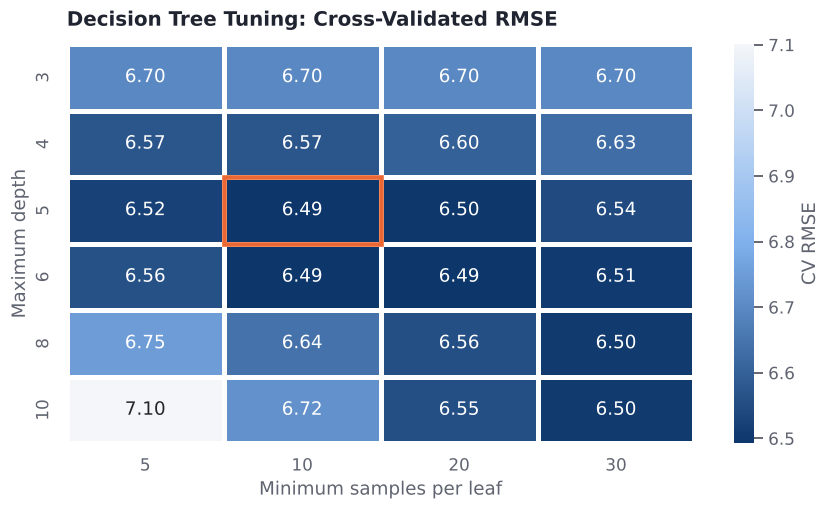

In [29]:
# Tune tree depth and minimum leaf size with 5-fold cross-validation on the training data
tree_parameters = {"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [5, 10, 20, 30]}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
tree_search = GridSearchCV(DecisionTreeRegressor(random_state=42), tree_parameters,
                           scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
tree_search.fit(X_train, y_train)
print("Best parameters:", tree_search.best_params_)
print("Best CV RMSE:", round(-tree_search.best_score_, 4))

# Cross-validated RMSE for every combination tried (lower is better; the best cell is outlined)
grid = (pd.DataFrame(tree_search.cv_results_)
        .assign(RMSE=lambda d: -d["mean_test_score"])
        .pivot(index="param_max_depth", columns="param_min_samples_leaf", values="RMSE"))
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(grid, annot=True, fmt=".2f", cmap=SEQUENTIAL.reversed(), linewidths=2, linecolor="white",
            cbar_kws={"label": "CV RMSE"}, ax=ax)
best_row = list(grid.index).index(tree_search.best_params_["max_depth"])
best_col = list(grid.columns).index(tree_search.best_params_["min_samples_leaf"])
ax.add_patch(plt.Rectangle((best_col, best_row), 1, 1, fill=False, edgecolor=ORANGE, linewidth=3))
finish(ax, "Decision Tree Tuning: Cross-Validated RMSE", "Minimum samples per leaf", "Maximum depth")
plt.tight_layout()
plt.show()

### Decision Tree Hyperparameter Tuning Results

Five-fold cross-validation identified a maximum tree depth of 5 and a minimum leaf size of 10 as the best combination among the parameters tested.

The selected model achieved a cross-validation RMSE of 6.4926 percentage points.

These settings limit tree complexity and help reduce the risk of overfitting. The cross-validation results provide an estimate of predictive performance before evaluating the model on the held-out testing dataset.

In [30]:
# Training and testing performance of the tuned tree
best_tree = tree_search.best_estimator_
tree_train_pred = best_tree.predict(X_train)
tree_test_pred = best_tree.predict(X_test)
tree_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "RMSE": [np.sqrt(mean_squared_error(y_train, tree_train_pred)), np.sqrt(mean_squared_error(y_test, tree_test_pred))],
    "MAE": [mean_absolute_error(y_train, tree_train_pred), mean_absolute_error(y_test, tree_test_pred)],
    "R²": [r2_score(y_train, tree_train_pred), r2_score(y_test, tree_test_pred)],
})
tree_results.round(4)

,Dataset,RMSE,MAE,R²
0,Training,6.0333,4.8387,0.5953
1,Testing,6.5781,5.2472,0.5064


### Decision Tree Regression Performance and Model Comparison

The Decision Tree Regression model achieved a training R² of 0.5953 and a testing R² of 0.5064, explaining approximately 50.64% of the variation in hospital recommendation percentages in the testing dataset.

The testing RMSE was 6.5781 percentage points, while the testing MAE was 5.2472 percentage points. The difference between training and testing performance suggests some reduction in predictive accuracy on unseen hospitals.

When compared with Multiple Linear Regression, the linear model performed better across all three testing metrics.

Multiple Linear Regression achieved a lower RMSE (6.2242 vs. 6.5781), a lower MAE (5.0115 vs. 5.2472), and a higher R² (0.5581 vs. 0.5064).

These findings suggest that Multiple Linear Regression provides more accurate predictions of hospital recommendation percentages than the tuned Decision Tree for this dataset and train-test split.

Although Decision Trees can capture nonlinear relationships, this additional flexibility did not improve predictive performance in our analysis.

Overall, Multiple Linear Regression is the preferred model for predicting hospital recommendation percentages based on the current results.

,Model,RMSE,MAE,R²
0,Multiple Linear Regression,6.2242,5.0115,0.5581
1,Decision Tree Regression,6.5781,5.2472,0.5064


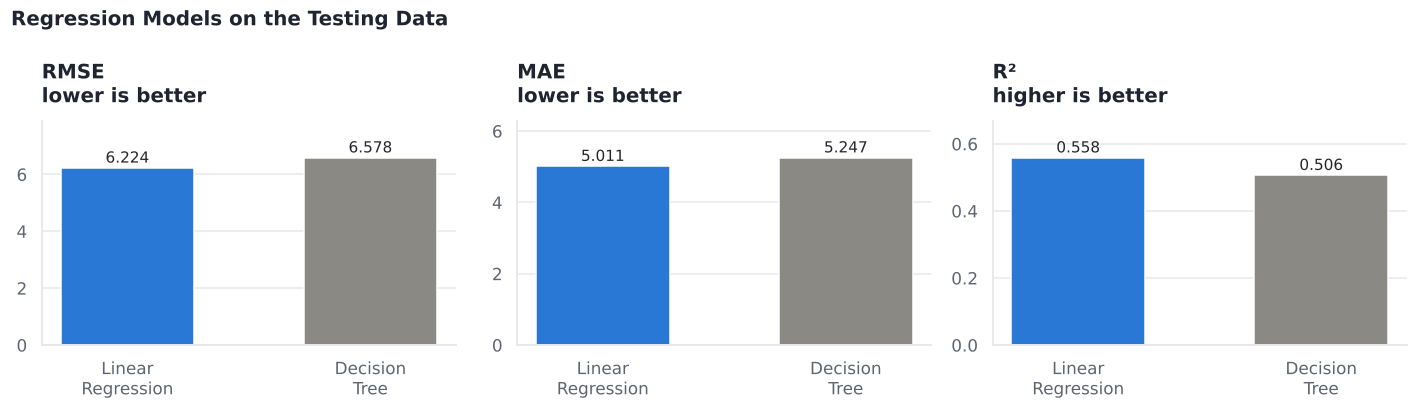

In [31]:
# Testing performance of both regression models side by side
regression_comparison = pd.DataFrame({
    "Model": ["Multiple Linear Regression", "Decision Tree Regression"],
    "RMSE": [regression_results.loc[1, "RMSE"], tree_results.loc[1, "RMSE"]],
    "MAE": [regression_results.loc[1, "MAE"], tree_results.loc[1, "MAE"]],
    "R²": [regression_results.loc[1, "R²"], tree_results.loc[1, "R²"]],
})
display(regression_comparison.round(4))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, metric, better in zip(axes, ["RMSE", "MAE", "R²"], ["lower is better", "lower is better", "higher is better"]):
    values = regression_comparison[metric]
    bars = ax.bar(["Linear\nRegression", "Decision\nTree"], values, color=[BLUE, GREY], width=0.55)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, v * 1.01, f"{v:.3f}", ha="center", va="bottom", fontsize=10)
    ax.set_ylim(0, values.max() * 1.2)
    ax.grid(axis="x", visible=False)
    finish(ax, metric, subtitle=better)
plt.suptitle("Regression Models on the Testing Data", x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

### Decision Tree Feature Importance

Feature importance scores were examined to identify which patient-experience measures contributed most to the Decision Tree's predictions.

The importance scores are based on how much each predictor reduces prediction error when used to split the training data.

These scores provide additional insight into the predictors used by the model, although they do not establish causal relationships.

,Importance
Nurse Communication,0.8332
Discharge Information,0.0535
Doctor Communication,0.0488
Night Quietness,0.0377
Room Cleanliness,0.0204
Medicine Explanation,0.0063


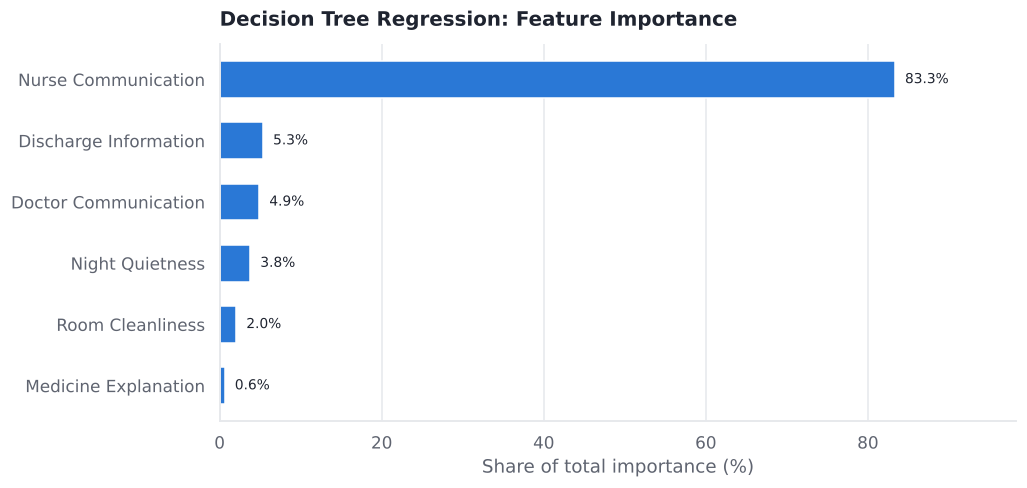

In [32]:
# Share of the tree's error reduction attributed to each predictor
tree_importance = pd.Series(best_tree.feature_importances_, index=PREDICTORS).sort_values(ascending=False)
display(tree_importance.rename(index=LABELS).to_frame("Importance").round(4))
importance_chart(tree_importance, "Decision Tree Regression: Feature Importance", "Share of total importance (%)")

### Interpretation of Decision Tree Feature Importance

The Decision Tree Regression model identified nurse communication as the most important predictor of hospital recommendation percentages, accounting for approximately 83.32% of the model's total reduction in the splitting criterion.

Discharge information (5.35%) and doctor communication (4.88%) were the next most important predictors, followed by night quietness (3.77%), room cleanliness (2.04%), and medicine explanation (0.63%).

This finding is consistent with our earlier correlation analysis, where nurse communication had the strongest positive correlation with hospital recommendation percentages (r ≈ 0.71).

However, these importance scores should be interpreted cautiously because several patient-experience measures are correlated. The Decision Tree may prioritize one predictor over others that contain similar information.

Overall, nurse communication emerged as the dominant predictor in our Decision Tree model, suggesting that it is particularly useful for predicting hospital recommendation percentages. These results indicate predictive associations rather than causal relationships.

### What the Regression Tree Looks Like

The chart shows the top three levels of the tuned tree. Each box gives the splitting rule, the number of training hospitals that reach it, and their average recommendation percentage (`value`).

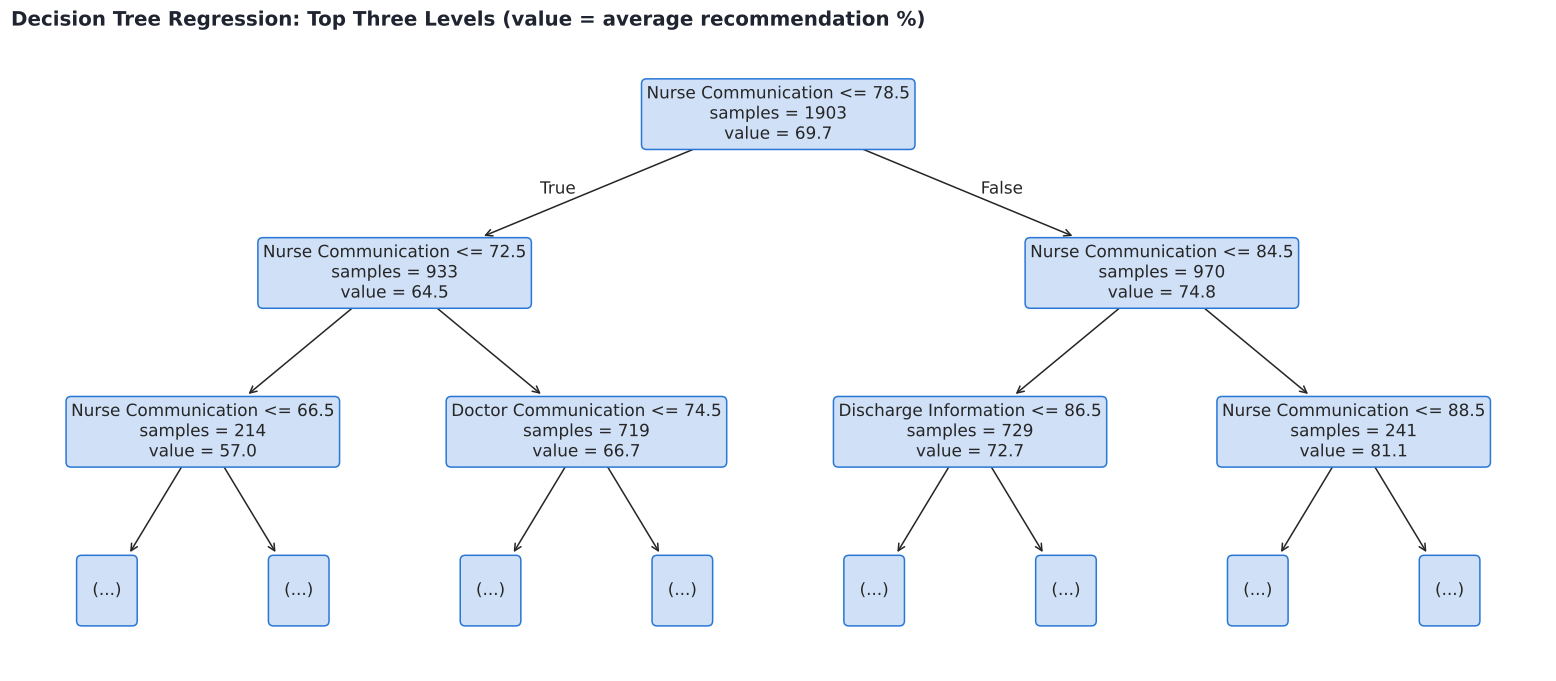

In [33]:
# Draw the top three levels of the tuned regression tree (deeper branches shown as "(...)")
fig, ax = plt.subplots(figsize=(18, 7.5))
nodes = plot_tree(best_tree, max_depth=2, feature_names=[LABELS[c] for c in PREDICTORS], rounded=True,
                  impurity=False, precision=1, fontsize=11, ax=ax)
for node in nodes:
    if node.get_bbox_patch() is not None:
        node.get_bbox_patch().set(facecolor=LIGHT_BLUE, edgecolor=BLUE)
ax.set_title("Decision Tree Regression: Top Three Levels (value = average recommendation %)", loc="left",
             fontsize=13, fontweight="bold", color=INK)
plt.show()

### Interpretation

The first split is nurse communication at 78.5%, and the second level splits on nurse communication again (72.5% on the left, 84.5% on the right). Hospitals with nurse communication at or below 72.5% average about 64.5% recommendation, while those above 84.5% average about 81%. Only at the third level do doctor communication (on the left) and discharge information (on the right) appear.

This explains why the tree gives nurse communication 83% of its importance: the tree uses it for almost all of the major splits, and once it has been used, the correlated communication measures add little new information.

# 5. Classification: Logistic Regression

Logistic Regression was used to predict whether a hospital achieves a high patient recommendation percentage (70% or higher).

The dependent variable is `target_high_recommend`, where:

- 1 represents hospitals with recommendation percentages of at least 70%.
- 0 represents hospitals with recommendation percentages below 70%.

The model uses six patient-experience measures as predictors: nurse communication, doctor communication, medicine explanation, discharge information, room cleanliness, and night quietness.

The dataset was divided into 60% training and 40% testing observations using stratified sampling to preserve the proportion of hospitals in each recommendation category.

Five-fold cross-validation will be used to tune the model before evaluating its performance on the testing dataset.

In [34]:
# Binary target and a stratified 60/40 split (keeps the share of high hospitals equal in both sets)
X_class = df[PREDICTORS].copy()
y_class = df[HIGH].astype(int)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_class, y_class, test_size=0.40, random_state=42, stratify=y_class)

print("Training observations:", len(Xc_train))
print("Testing observations:", len(Xc_test))
pd.DataFrame({
    "Overall (%)": y_class.value_counts(normalize=True) * 100,
    "Training (%)": yc_train.value_counts(normalize=True) * 100,
    "Testing (%)": yc_test.value_counts(normalize=True) * 100,
}).rename(index={1: "High (≥70%)", 0: "Lower (<70%)"}).round(2)

Training observations: 1903
Testing observations: 1269


,Overall (%),Training (%),Testing (%)
target_high_recommend,,,
High (≥70%),52.05,52.02,52.09
Lower (<70%),47.95,47.98,47.91


### Logistic Regression Model Development

A Logistic Regression model was developed to classify hospitals into high-recommendation (≥70%) and lower-recommendation (<70%) categories.

The six patient-experience measures were standardized before fitting the model. Standardization was performed within a pipeline to prevent information from the validation folds from influencing the training process.

Five-fold stratified cross-validation was used to select the regularization strength (C). The model was optimized using the F1-score, which balances precision and recall for the high-recommendation category.

The final model will be evaluated using the held-out testing dataset.

In [35]:
# Standardize inside a pipeline, then tune the regularization strength C with stratified 5-fold CV on F1
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=2000, random_state=42)),
])
cv_class = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logistic_search = GridSearchCV(logistic_pipeline, {"logistic__C": [0.01, 0.1, 1, 10, 100]},
                               scoring="f1", cv=cv_class, n_jobs=-1)
logistic_search.fit(Xc_train, yc_train)
print("Best parameters:", logistic_search.best_params_)
print("Best CV F1-score:", round(logistic_search.best_score_, 4))

Best parameters: {'logistic__C': 1}
Best CV F1-score: 0.7739


### Logistic Regression Hyperparameter Tuning Results

Five-fold stratified cross-validation identified C = 1 as the best regularization strength among the values tested.

The model achieved an average cross-validation F1-score of 0.7739, indicating a reasonable balance between precision and recall when identifying hospitals with recommendation percentages of at least 70%.

The selected model was then evaluated on the held-out testing dataset to assess its performance on unseen hospitals.

In [36]:
def classification_scores(name, y_true, y_pred):
    # Accuracy, precision, recall and F1 for the high-recommendation class
    return pd.DataFrame({"Model": [name], "Accuracy": [accuracy_score(y_true, y_pred)],
                         "Precision": [precision_score(y_true, y_pred)], "Recall": [recall_score(y_true, y_pred)],
                         "F1-score": [f1_score(y_true, y_pred)]})


# Evaluate the tuned logistic regression on the testing data
best_logistic = logistic_search.best_estimator_
logistic_test_pred = best_logistic.predict(Xc_test)
logistic_results = classification_scores("Logistic Regression", yc_test, logistic_test_pred)
display(logistic_results.round(4))
print("Classification Report:")
print(classification_report(yc_test, logistic_test_pred, target_names=["Lower (<70%)", "High (≥70%)"]))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7407,0.7492,0.7549,0.7521


Classification Report:
              precision    recall  f1-score   support

Lower (<70%)       0.73      0.73      0.73       608
 High (≥70%)       0.75      0.75      0.75       661

    accuracy                           0.74      1269
   macro avg       0.74      0.74      0.74      1269
weighted avg       0.74      0.74      0.74      1269



### Logistic Regression Performance Interpretation

The Logistic Regression model achieved a testing accuracy of 74.07%, correctly classifying 940 out of 1,269 hospitals.

The model obtained a precision of 74.92%, recall of 75.49%, and F1-score of 75.21% for identifying hospitals with recommendation percentages of at least 70%.

The confusion matrix showed that the model correctly identified 441 lower-recommendation hospitals and 499 high-recommendation hospitals. However, it incorrectly classified 167 lower-recommendation hospitals as high recommendation and 162 high-recommendation hospitals as lower recommendation.

The testing F1-score (0.7521) was slightly lower than the cross-validation F1-score (0.7739), suggesting some reduction in performance on unseen hospitals.

Overall, Logistic Regression demonstrated reasonable classification performance, correctly identifying approximately three out of four hospitals.

These results provide a baseline for comparing Logistic Regression with Classification Tree.

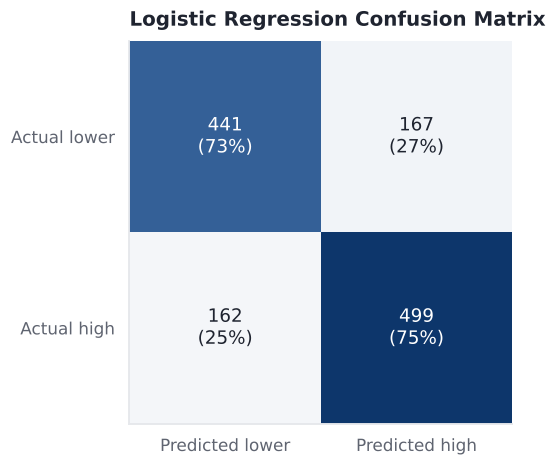

In [37]:
# Confusion matrix for logistic regression
fig, ax = plt.subplots(figsize=(5.2, 4.4))
confusion_panel(ax, confusion_matrix(yc_test, logistic_test_pred), "Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

## 5.1 Classification Tree

A Classification Tree was developed to predict whether a hospital achieves a patient recommendation percentage of at least 70%.

The model uses the same six patient-experience predictors and the same stratified 60/40 training and testing datasets used for Logistic Regression.

Five-fold stratified cross-validation was used to select the tree's optimal complexity and reduce the risk of overfitting.

The model will be evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. Its performance will then be compared with Logistic Regression.

In [38]:
# Tune the classification tree with stratified 5-fold CV on F1
classification_tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [5, 10, 20, 30]},
    scoring="f1", cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), n_jobs=-1)
classification_tree_search.fit(Xc_train, yc_train)
print("Best parameters:", classification_tree_search.best_params_)
print("Best CV F1-score:", round(classification_tree_search.best_score_, 4))

Best parameters: {'max_depth': 5, 'min_samples_leaf': 30}
Best CV F1-score: 0.779


### Classification Tree Hyperparameter Tuning Results

Five-fold stratified cross-validation identified a maximum tree depth of 5 and a minimum leaf size of 30 as the best combination among the parameters tested.

The Classification Tree achieved an average cross-validation F1-score of 0.7790, slightly higher than the Logistic Regression model's F1-score of 0.7739.

Although the Classification Tree performed marginally better during cross-validation, the difference was small. Both models will be evaluated on the same held-out testing dataset to determine which provides better classification performance.

In [39]:
# Evaluate the tuned classification tree on the testing data
best_classification_tree = classification_tree_search.best_estimator_
tree_class_test_pred = best_classification_tree.predict(Xc_test)
classification_tree_results = classification_scores("Classification Tree", yc_test, tree_class_test_pred)
display(classification_tree_results.round(4))
print("Classification Report:")
print(classification_report(yc_test, tree_class_test_pred, target_names=["Lower (<70%)", "High (≥70%)"]))

,Model,Accuracy,Precision,Recall,F1-score
0,Classification Tree,0.7376,0.7271,0.7943,0.7592


Classification Report:
              precision    recall  f1-score   support

Lower (<70%)       0.75      0.68      0.71       608
 High (≥70%)       0.73      0.79      0.76       661

    accuracy                           0.74      1269
   macro avg       0.74      0.74      0.74      1269
weighted avg       0.74      0.74      0.74      1269



### Classification Tree Performance and Model Comparison

The Classification Tree achieved a testing accuracy of 73.76%, correctly classifying 936 out of 1,269 hospitals.

The model obtained a precision of 72.71%, recall of 79.43%, and F1-score of 75.92% for identifying high-recommendation hospitals.

The confusion matrix showed that the model correctly identified 411 lower-recommendation hospitals and 525 high-recommendation hospitals. However, it incorrectly classified 197 lower-recommendation hospitals as high recommendation and 136 high-recommendation hospitals as lower recommendation.

When compared with Logistic Regression, the results showed mixed performance.

Logistic Regression achieved slightly higher accuracy (74.07% vs. 73.76%) and precision (74.92% vs. 72.71%).

However, Classification Tree achieved higher recall (79.43% vs. 75.49%) and a slightly higher F1-score (75.92% vs. 75.21%).

These findings suggest that Logistic Regression is slightly better at overall classification and avoiding false positives, while Classification Tree is better at identifying high-recommendation hospitals.

Since F1-score was used for model tuning, Classification Tree has a small advantage on this metric. However, the difference is limited, and neither model consistently outperformed the other across all evaluation measures.

Overall, both models demonstrated comparable predictive performance.

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7407,0.7492,0.7549,0.7521
1,Classification Tree,0.7376,0.7271,0.7943,0.7592


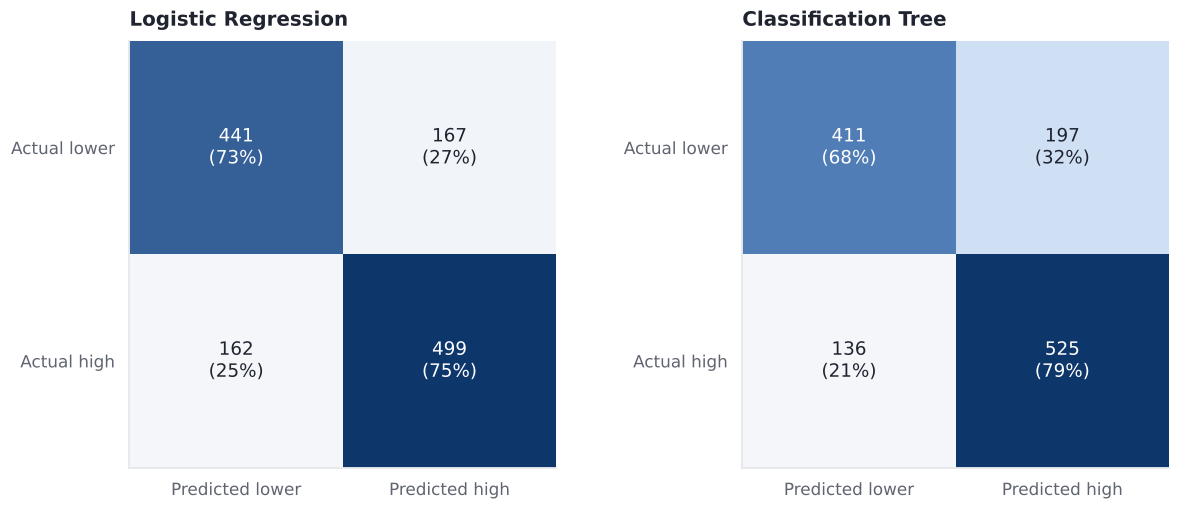

In [40]:
# Both classifiers side by side
classification_comparison = pd.concat([logistic_results, classification_tree_results], ignore_index=True)
display(classification_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
confusion_panel(axes[0], confusion_matrix(yc_test, logistic_test_pred), "Logistic Regression")
confusion_panel(axes[1], confusion_matrix(yc_test, tree_class_test_pred), "Classification Tree")
plt.tight_layout()
plt.show()

### Classification Tree Feature Importance

Feature importance scores were examined to identify which patient-experience dimensions contributed most to the Classification Tree's predictions.

The scores measure each predictor's contribution to reducing impurity across the tree's splits.

These results will help determine whether the predictors emphasized by the Classification Tree are consistent with those identified in our earlier regression analysis.

Because several patient-experience measures are correlated, feature importance scores will be interpreted cautiously and will not be treated as evidence of causation.

,Importance (%)
Discharge Information,56.82
Nurse Communication,22.40
Night Quietness,8.52
Doctor Communication,7.67
Room Cleanliness,2.65
Medicine Explanation,1.93


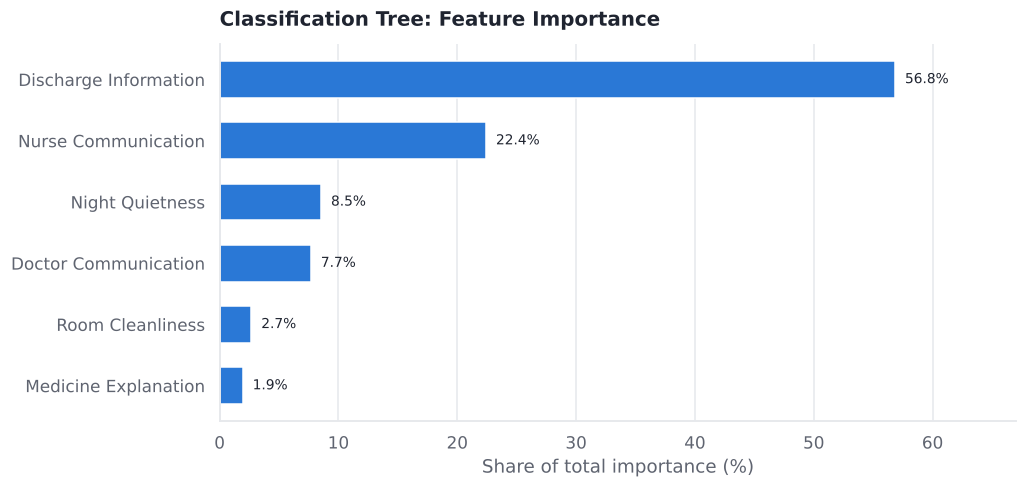

In [41]:
# Share of the tree's impurity reduction attributed to each predictor
classification_importance = pd.Series(best_classification_tree.feature_importances_, index=PREDICTORS).sort_values(ascending=False)
display((classification_importance * 100).rename(index=LABELS).to_frame("Importance (%)").round(2))
importance_chart(classification_importance, "Classification Tree: Feature Importance", "Share of total importance (%)")

### Interpretation of Classification Tree Feature Importance

The Classification Tree identified discharge information as the most important predictor of high hospital recommendation status, accounting for approximately 56.82% of the model's total reduction in impurity.

Nurse communication was the second most important predictor (22.40%), followed by night quietness (8.52%), doctor communication (7.67%), room cleanliness (2.65%), and medicine explanation (1.93%).

Interestingly, these findings differ from our Decision Tree Regression results, where nurse communication accounted for approximately 83.32% of feature importance.

This difference may reflect the models' different prediction objectives. While Decision Tree Regression predicts recommendation percentages, Classification Tree predicts whether a hospital reaches the 70% recommendation threshold.

The results suggest that nurse communication and discharge information are particularly useful predictors across our tree-based analyses.

However, because several patient-experience dimensions are correlated, the importance scores should not be interpreted as causal effects or as definitive rankings of what matters most to patients.

### Permutation Feature Importance

Permutation importance was used to further examine which patient-experience dimensions contribute most to the Classification Tree's predictive performance.

Each predictor was randomly shuffled while the other predictors remained unchanged. The resulting decrease in F1-score was used to measure its importance.

The analysis was conducted on the held-out testing dataset using 20 repetitions to assess the consistency of the importance scores.

Because several patient-experience measures are correlated, permutation importance may underestimate the contribution of predictors that contain overlapping information.

,Mean Importance,Std Importance
Discharge Information,0.0803,0.0079
Night Quietness,0.0246,0.0060
Nurse Communication,0.0168,0.0045
Doctor Communication,0.0111,0.0039
Room Cleanliness,0.0036,0.0047
Medicine Explanation,0.0000,0.0000


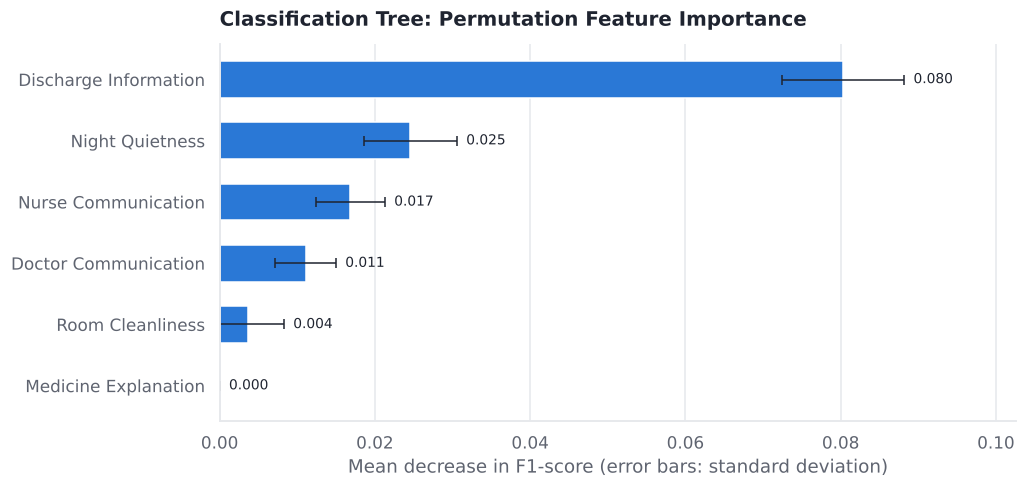

In [42]:
# Permutation importance on the testing data: drop in F1 when one predictor is shuffled (20 repeats)
perm_results = permutation_importance(best_classification_tree, Xc_test, yc_test, scoring="f1",
                                      n_repeats=20, random_state=42, n_jobs=-1)
permutation_df = pd.DataFrame({"Mean Importance": perm_results.importances_mean,
                               "Std Importance": perm_results.importances_std}, index=PREDICTORS)
permutation_df = permutation_df.sort_values("Mean Importance", ascending=False)
display(permutation_df.rename(index=LABELS).round(4))
importance_chart(permutation_df["Mean Importance"], "Classification Tree: Permutation Feature Importance",
                 "Mean decrease in F1-score (error bars: standard deviation)", as_percent=False,
                 errors=permutation_df["Std Importance"])

### Interpretation of Permutation Feature Importance

Permutation importance was used to evaluate how much each patient-experience dimension contributed to the Classification Tree's F1-score on the testing dataset.

Discharge information had the highest permutation importance (0.0803), indicating that randomly shuffling this predictor reduced the model's F1-score by approximately 0.0803 on average.

Night quietness ranked second (0.0246), followed by nurse communication (0.0168) and doctor communication (0.0111).

Room cleanliness had a relatively small importance score (0.0036), while medicine explanation had an importance score of zero, indicating that shuffling it did not affect the model's F1-score in this analysis.

These findings are generally consistent with the Classification Tree's built-in feature importance results, particularly for discharge information, which ranked first under both methods.

However, night quietness ranked above nurse communication in the permutation analysis, suggesting that the two methods capture different aspects of predictor importance.

Overall, discharge information emerged as the strongest predictor of high-recommendation status in our Classification Tree. Nurse communication and night quietness also contributed to predictive performance.

Because the patient-experience measures are correlated, these findings should be interpreted as model-specific predictive associations rather than causal effects or definitive rankings of patient priorities.

### Logistic Regression Coefficients and Odds Ratios

The Logistic Regression coefficients were examined to understand how patient-experience dimensions are associated with the likelihood of achieving a high hospital recommendation percentage (≥70%).

Because the predictors were standardized before model fitting, each coefficient represents the change in log-odds associated with a one-standard-deviation increase in the corresponding predictor, holding the other variables constant.

Odds ratios were calculated by exponentiating the coefficients.

An odds ratio greater than 1 indicates higher predicted odds of achieving high-recommendation status, while an odds ratio below 1 indicates lower predicted odds.

These relationships are associative rather than causal.

,Coefficient,Odds Ratio
Discharge Information,0.8349,2.3047
Doctor Communication,0.5758,1.7786
Nurse Communication,0.4190,1.5205
Night Quietness,0.3357,1.3990
Room Cleanliness,0.2599,1.2968
Medicine Explanation,-0.0474,0.9537


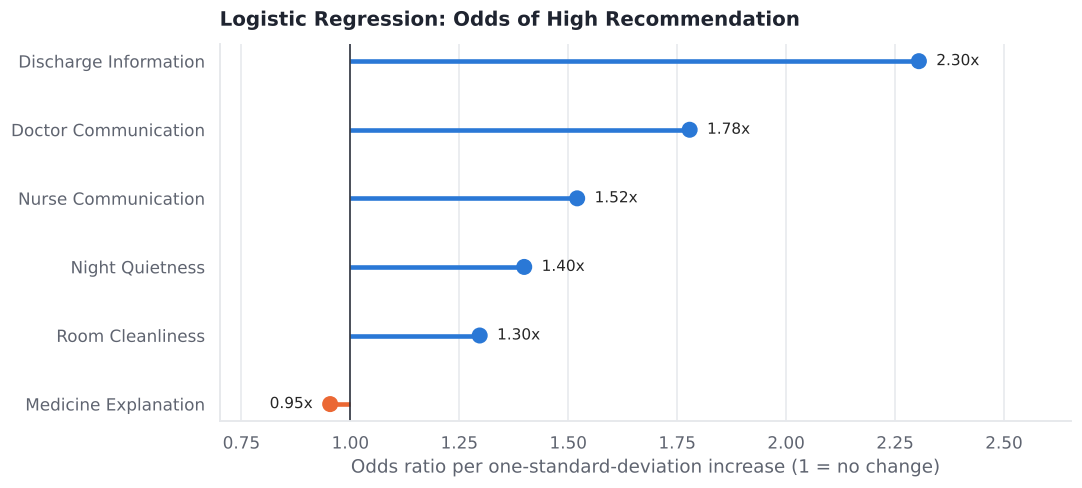

In [43]:
# Coefficients and odds ratios (per one standard deviation, because predictors were standardized)
logistic_model = best_logistic.named_steps["logistic"]
logistic_effects = pd.DataFrame({"Coefficient": logistic_model.coef_[0],
                                 "Odds Ratio": np.exp(logistic_model.coef_[0])}, index=PREDICTORS)
logistic_effects = logistic_effects.reindex(logistic_effects["Coefficient"].abs().sort_values(ascending=False).index)
display(logistic_effects.rename(index=LABELS).round(4))

# Lollipop chart of odds ratios; the line at 1 means no change in odds
odds = logistic_effects["Odds Ratio"].rename(index=LABELS).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.6))
colors = [BLUE if v > 1 else ORANGE for v in odds.values]
ax.hlines(range(len(odds)), 1, odds.values, color=colors, linewidth=3)
ax.scatter(odds.values, range(len(odds)), color=colors, s=90, zorder=3)
for i, v in enumerate(odds.values):
    ax.text(v + (0.04 if v > 1 else -0.04), i, f"{v:.2f}x", va="center", ha="left" if v > 1 else "right", fontsize=10)
ax.axvline(1, color=INK, linewidth=1)
ax.set_yticks(range(len(odds)), odds.index)
ax.set_xlim(0.7, odds.max() + 0.35)
ax.grid(axis="y", visible=False)
finish(ax, "Logistic Regression: Odds of High Recommendation",
       "Odds ratio per one-standard-deviation increase (1 = no change)")
plt.tight_layout()
plt.show()

### Interpretation of Logistic Regression Coefficients and Odds Ratios

The Logistic Regression results identified discharge information as having the strongest positive association with high hospital recommendation status.

Its odds ratio of 2.3047 indicates that a one-standard-deviation increase in discharge information scores is associated with approximately 130.47% higher odds of achieving a recommendation percentage of at least 70%, holding the other predictors constant.

Doctor communication (OR = 1.7786) and nurse communication (OR = 1.5205) also showed positive associations with high-recommendation status, followed by night quietness (OR = 1.3990) and room cleanliness (OR = 1.2968).

Medicine explanation had a small negative coefficient (OR = 0.9537). However, this result should be interpreted cautiously because several patient-experience measures are correlated.

Importantly, discharge information also ranked first in the Classification Tree's built-in feature importance and permutation importance analyses.

These consistent findings suggest that discharge information is a particularly useful predictor of whether hospitals achieve high-recommendation status.

However, the results represent predictive associations rather than causal relationships, and the regularized Logistic Regression coefficients do not establish statistical significance.

## 5.2 Random Forest Classification (Ensemble Extension)

As an ensemble extension, we fit a Random Forest on **the same stratified 60/40 classification split** used for Logistic Regression and the Classification Tree. This is a fresh fit on the shared split, not a copy of metrics from an earlier analysis that used a different split. The hyperparameters below are an exploratory specification informed by an earlier exploratory Random Forest analysis; they are not claimed to have been tuned using this consolidated test set.

In [44]:
# Random Forest on the same stratified split as the other classifiers
rf_group = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_group.fit(Xc_train, yc_train)
rf_pred = rf_group.predict(Xc_test)
rf_prob = rf_group.predict_proba(Xc_test)[:, 1]

rf_group_results = classification_scores("Random Forest", yc_test, rf_pred)
rf_group_results["ROC-AUC"] = roc_auc_score(yc_test, rf_prob)
display(rf_group_results.round(4))

# Cross-validated F1 on the training data only
rf_cv_f1 = cross_val_score(rf_group, Xc_train, yc_train, cv=cv_class, scoring="f1", n_jobs=-1)
print(f"Random Forest 5-fold CV F1: {rf_cv_f1.mean():.4f} ± {rf_cv_f1.std():.4f}")

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.7478,0.7398,0.7958,0.7668,0.837


Random Forest 5-fold CV F1: 0.7859 ± 0.0096


,Random Forest importance
Nurse Communication,0.2297
Doctor Communication,0.2244
Discharge Information,0.2098
Medicine Explanation,0.1292
Night Quietness,0.1142
Room Cleanliness,0.0926


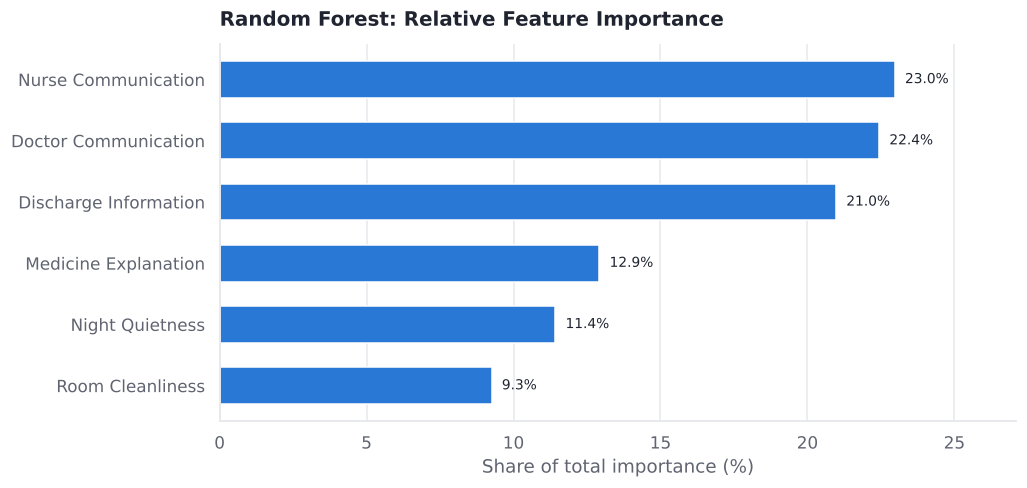

In [45]:
# Random Forest feature importance (model-specific, not causal)
rf_importance_group = pd.Series(rf_group.feature_importances_, index=PREDICTORS).sort_values(ascending=False)
display(rf_importance_group.rename(index=LABELS).to_frame("Random Forest importance").round(4))
importance_chart(rf_importance_group, "Random Forest: Relative Feature Importance", "Share of total importance (%)")

### Interpreting the Ensemble Extension

Unlike the single classification tree, the Random Forest spreads importance fairly evenly across the three communication measures: nurse communication (23.0%), doctor communication (22.4%) and discharge information (21.0%), with the other three measures between 9% and 13%. Because each tree in the forest sees random subsets of the data and predictors, correlated measures take turns being used, so importance is shared between them. This is a reminder that importance from any one tree depends on which of several overlapping predictors it happens to pick first; feature importance should not be read as a causal effect or a unique share of explanatory power.

These consolidated results supersede the earlier exploratory 80/20-split metrics for group-level comparisons.

## 5.3 Comparing the Three Classifiers

All three classifiers are evaluated on exactly the same held-out hospitals. The ROC curve shows how well each model ranks high-recommendation hospitals above lower ones at every possible threshold (ROC-AUC of 0.5 is chance, 1.0 is perfect); the bar chart compares the threshold-based metrics.

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7407,0.7492,0.7549,0.7521,0.8319
1,Classification Tree,0.7376,0.7271,0.7943,0.7592,0.8139
2,Random Forest,0.7478,0.7398,0.7958,0.7668,0.8370


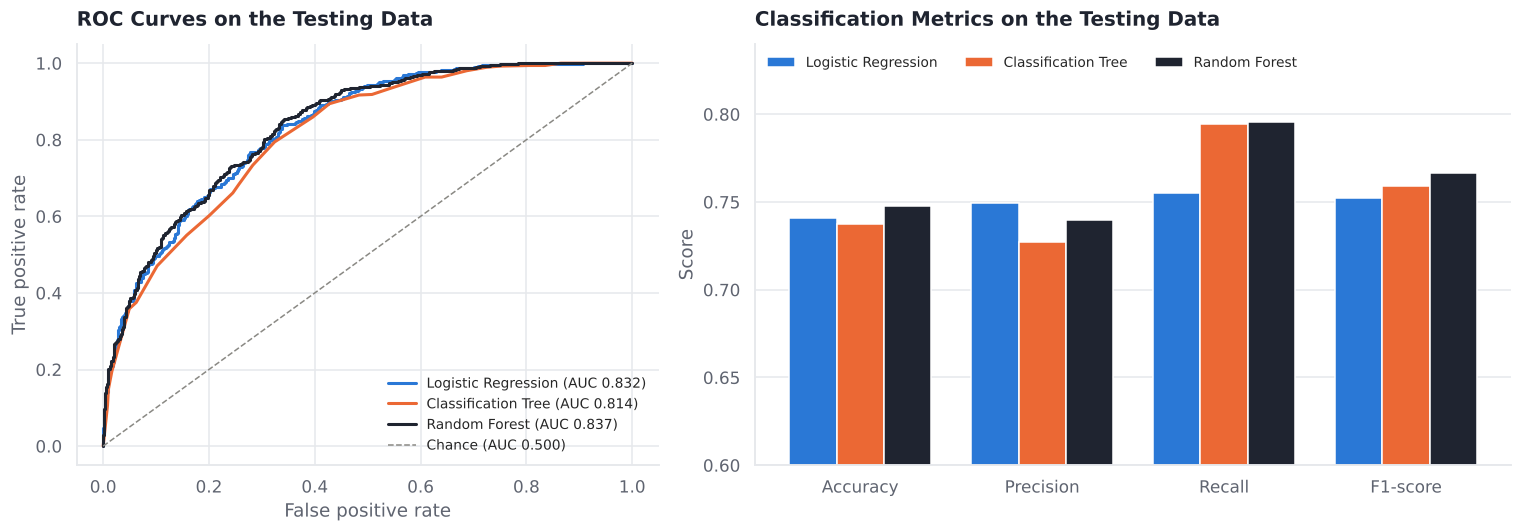

In [46]:
# Probabilities of the high class from each model, and their ROC-AUC
probabilities = {
    "Logistic Regression": best_logistic.predict_proba(Xc_test)[:, 1],
    "Classification Tree": best_classification_tree.predict_proba(Xc_test)[:, 1],
    "Random Forest": rf_prob,
}
classification_group_comparison = pd.concat([logistic_results, classification_tree_results,
                                             rf_group_results.drop(columns="ROC-AUC")], ignore_index=True)
classification_group_comparison["ROC-AUC"] = [roc_auc_score(yc_test, p) for p in probabilities.values()]
display(classification_group_comparison.round(4))

model_colors = {"Logistic Regression": BLUE, "Classification Tree": ORANGE, "Random Forest": INK}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.3]})

# ROC curves
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(yc_test, prob)
    axes[0].plot(fpr, tpr, color=model_colors[name], linewidth=2, label=f"{name} (AUC {roc_auc_score(yc_test, prob):.3f})")
axes[0].plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="Chance (AUC 0.500)")
axes[0].legend(frameon=False, loc="lower right", fontsize=9)
finish(axes[0], "ROC Curves on the Testing Data", "False positive rate", "True positive rate")

# Grouped bars of the threshold-based metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
width = 0.26
for i, (_, row) in enumerate(classification_group_comparison.iterrows()):
    positions = np.arange(len(metrics)) + (i - 1) * width
    axes[1].bar(positions, row[metrics].astype(float), width, color=model_colors[row["Model"]], label=row["Model"])
axes[1].set_xticks(np.arange(len(metrics)), metrics)
axes[1].set_ylim(0.6, 0.84)
axes[1].legend(frameon=False, ncol=3, loc="upper left", fontsize=9)
axes[1].grid(axis="x", visible=False)
finish(axes[1], "Classification Metrics on the Testing Data", None, "Score")
plt.tight_layout()
plt.show()

### Interpretation

The three classifiers perform very similarly. The Random Forest is slightly best on accuracy (74.8%), recall (79.6%), F1-score (0.767) and ROC-AUC (0.837), logistic regression has the highest precision (74.9%) and an AUC of 0.832, and the classification tree has an AUC of 0.814. The ROC curves for the Random Forest and logistic regression almost overlap.

The gains from the Random Forest are about one percentage point or less on a single test split, which is not strong evidence of a real improvement. Because logistic regression is almost as accurate and much easier to explain (through its odds ratios), it remains a sensible choice for communicating results; the Random Forest is the choice if the only aim is the highest recall when flagging hospitals likely to reach the 70% threshold.

# 6. Summary of Predictive Modeling Results

Four core supervised learning models, plus a Random Forest extension, were developed to investigate how patient-experience measures predict hospital recommendations.

Two regression models predicted the actual hospital recommendation percentage, while two classification models predicted whether a hospital achieved a recommendation percentage of at least 70%.

All models used six patient-experience predictors, a 60/40 training-testing split, and the same testing observations within each modeling task.

Five-fold cross-validation was used to tune the Decision Tree Regression, Logistic Regression, and Classification Tree models.

The following tables summarize model performance on the held-out testing datasets.

In [47]:
# Testing results for every supervised model
print("REGRESSION MODEL COMPARISON")
display(regression_comparison.round(4))
print("CLASSIFICATION MODEL COMPARISON")
display(classification_group_comparison.round(4))

REGRESSION MODEL COMPARISON


,Model,RMSE,MAE,R²
0,Multiple Linear Regression,6.2242,5.0115,0.5581
1,Decision Tree Regression,6.5781,5.2472,0.5064


CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7407,0.7492,0.7549,0.7521,0.8319
1,Classification Tree,0.7376,0.7271,0.7943,0.7592,0.8139
2,Random Forest,0.7478,0.7398,0.7958,0.7668,0.8370


## 6.1 Multiple Linear Regression Cross-Validation

Five-fold cross-validation was conducted on the training dataset to assess the stability of the Multiple Linear Regression model.

Root Mean Squared Error (RMSE) was calculated across the five validation folds.

This analysis provides an additional estimate of predictive performance and allows us to compare the cross-validation results with the model's performance on the held-out testing dataset.

Linear regression RMSE for each fold: [5.7884 6.3902 5.9209 6.2168 6.105 ]
Mean CV RMSE: 6.0843 | Standard Deviation: 0.2125
Decision tree RMSE for each fold: [6.2512 6.817  6.2936 6.5727 6.5283]


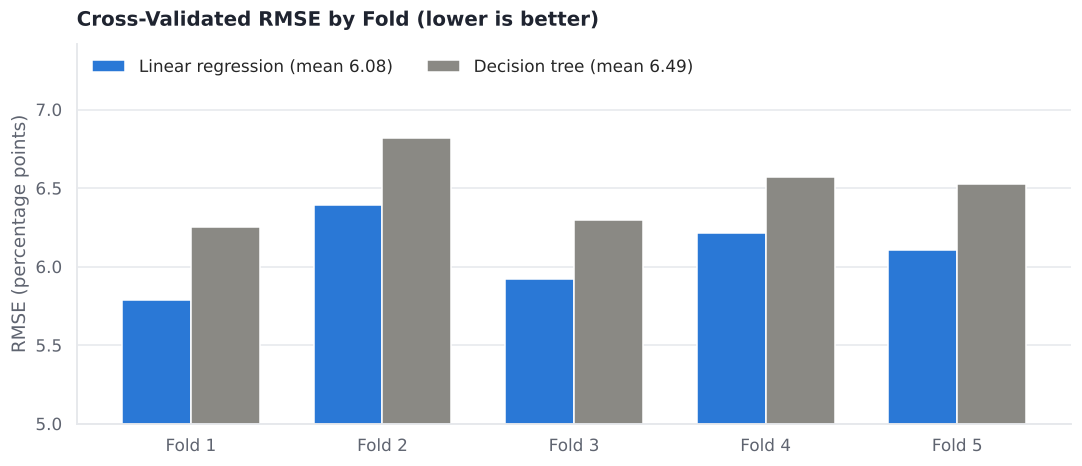

In [48]:
# 5-fold cross-validated RMSE on the training data for the linear model and the tuned tree (same folds)
linear_cv = KFold(n_splits=5, shuffle=True, random_state=42)
linear_cv_rmse = -cross_val_score(LinearRegression(), X_train, y_train, cv=linear_cv,
                                  scoring="neg_root_mean_squared_error", n_jobs=-1)
tree_cv_rmse = -cross_val_score(best_tree, X_train, y_train, cv=linear_cv,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
print("Linear regression RMSE for each fold:", linear_cv_rmse.round(4))
print("Mean CV RMSE:", round(linear_cv_rmse.mean(), 4), "| Standard Deviation:", round(linear_cv_rmse.std(), 4))
print("Decision tree RMSE for each fold:", tree_cv_rmse.round(4))

# Fold-by-fold comparison of the two regression models
fig, ax = plt.subplots(figsize=(10, 4.4))
folds = np.arange(1, 6)
ax.bar(folds - 0.18, linear_cv_rmse, 0.36, color=BLUE, label=f"Linear regression (mean {linear_cv_rmse.mean():.2f})")
ax.bar(folds + 0.18, tree_cv_rmse, 0.36, color=GREY, label=f"Decision tree (mean {tree_cv_rmse.mean():.2f})")
ax.set_xticks(folds, [f"Fold {f}" for f in folds])
ax.set_ylim(5, max(tree_cv_rmse.max(), linear_cv_rmse.max()) + 0.6)
ax.legend(frameon=False, ncol=2, loc="upper left")
ax.grid(axis="x", visible=False)
finish(ax, "Cross-Validated RMSE by Fold (lower is better)", None, "RMSE (percentage points)")
plt.tight_layout()
plt.show()

### Interpretation of Multiple Linear Regression Cross-Validation

Five-fold cross-validation was performed on the training dataset to assess the stability of the Multiple Linear Regression model.

The model achieved a mean cross-validation RMSE of 6.0843 percentage points, with a standard deviation of 0.2125 across the five folds.

The relatively small variation in RMSE suggests that the model performed consistently across different validation subsets.

The testing RMSE was 6.2242, only slightly higher than the mean cross-validation RMSE, suggesting reasonable generalization to unseen hospitals.

Compared with Decision Tree Regression, which achieved a cross-validation RMSE of 6.4926 and a testing RMSE of 6.5781, Multiple Linear Regression demonstrated better predictive performance.

Overall, these results provide additional support for selecting Multiple Linear Regression as the preferred model for predicting hospital recommendation percentages.

# 7. Business Prioritization

The descriptive and predictive results answer different questions: **performance** tells us which experiences are currently rated lowest; **predictive importance** helps identify which experiences are more closely associated with recommendation outcomes. This section combines the two perspectives without claiming that observed associations are causal.

We use the same six dimensions and a transparent, descriptive ranking: the mean score for current performance and the difference in average scores between high- and lower-recommendation hospitals as a **group-separation indicator**. Group differences are not adjusted model effects or causal impacts. Hospital managers should consider feasibility, patient safety, and local context before choosing interventions.

,Dimension,National mean (%),High-minus-lower gap (pp)
5,Night Quietness,57.15,7.88
4,Room Cleanliness,71.73,6.26
2,Medicine Explanation,60.65,6.21
0,Nurse Communication,78.66,5.60
1,Doctor Communication,78.43,5.25
3,Discharge Information,86.08,3.84


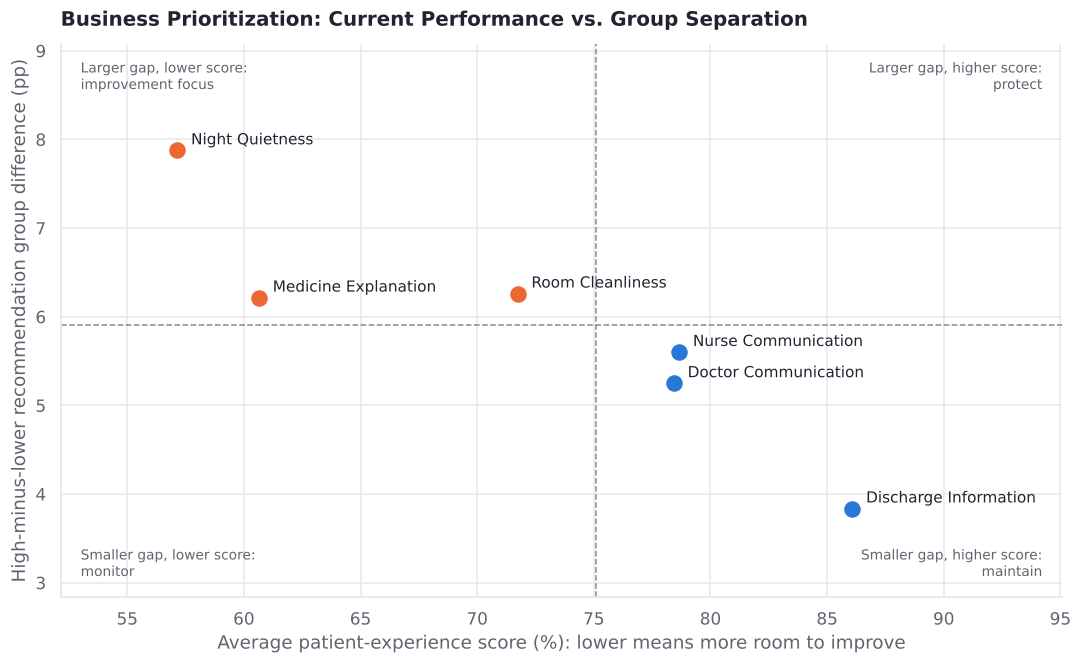

In [49]:
# Current performance (national mean) against group separation (high minus lower difference)
priority_table = pd.DataFrame({
    "Dimension": [LABELS[c] for c in PREDICTORS],
    "National mean (%)": df[PREDICTORS].mean().values,
    "High-minus-lower gap (pp)": (high_group[PREDICTORS].mean() - lower_group[PREDICTORS].mean()).values,
}).sort_values("High-minus-lower gap (pp)", ascending=False)
display(priority_table.round(2))

# Quadrant chart split at the median of each axis; top-left = large gap and low current score
x_mid = priority_table["National mean (%)"].median()
y_mid = priority_table["High-minus-lower gap (pp)"].median()
fig, ax = plt.subplots(figsize=(10, 6.2))
for _, row in priority_table.iterrows():
    focus = row["National mean (%)"] < x_mid and row["High-minus-lower gap (pp)"] >= y_mid
    ax.scatter(row["National mean (%)"], row["High-minus-lower gap (pp)"], s=140,
               color=ORANGE if focus else BLUE, edgecolor="white", zorder=3)
    ax.annotate(row["Dimension"], (row["National mean (%)"], row["High-minus-lower gap (pp)"]),
                xytext=(9, 4), textcoords="offset points", fontsize=10, color=INK)
ax.axvline(x_mid, color=GREY, linestyle="--", linewidth=1)
ax.axhline(y_mid, color=GREY, linestyle="--", linewidth=1)
corners = [(0.02, 0.97, "Larger gap, lower score:\nimprovement focus", "left", "top"),
           (0.98, 0.97, "Larger gap, higher score:\nprotect", "right", "top"),
           (0.02, 0.03, "Smaller gap, lower score:\nmonitor", "left", "bottom"),
           (0.98, 0.03, "Smaller gap, higher score:\nmaintain", "right", "bottom")]
for x, y, text, ha, va in corners:
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=9, color=MUTED)
ax.set_xlim(priority_table["National mean (%)"].min() - 5, priority_table["National mean (%)"].max() + 9)
ax.set_ylim(priority_table["High-minus-lower gap (pp)"].min() - 1, priority_table["High-minus-lower gap (pp)"].max() + 1.2)
finish(ax, "Business Prioritization: Current Performance vs. Group Separation",
       "Average patient-experience score (%): lower means more room to improve",
       "High-minus-lower recommendation group difference (pp)")
plt.tight_layout()
plt.show()

### Interpretation

The chart splits the six measures at the median of each axis. **Night quietness, medicine explanation and room cleanliness** fall in the improvement-focus quadrant: they have the lowest current scores and the largest raw differences between high- and lower-recommendation hospitals. Nurse and doctor communication have higher scores and moderate gaps, and discharge information is already high with the smallest gap, so it is mainly a measure to maintain.

This view complements the models rather than replacing them. The predictive models (especially logistic regression and the trees) rank discharge information and the communication measures highest once the other measures are held constant, so the quadrant chart identifies where there is room to improve, while the models identify which measures carry the most predictive information.

### Practical Recommendations and Responsible Use

1. **Communication:** Consider nurse communication and clear discharge explanations as priorities, supported by the regression/classification evidence and the importance-versus-performance chart. Test approaches such as teach-back, bedside handovers and plain-language discharge checklists locally rather than assuming their effect.
2. **Low-scoring experiences:** Nighttime quietness and medicine explanations have lower national scores; use local patient feedback to identify feasible improvements, even when their adjusted model importance is smaller.
3. **Benchmarking:** Compare hospitals with similar context where possible. Completed-survey count measures **survey volume, not hospital size**; do not present it as a bed-count proxy.
4. **Evaluation:** Track each intervention's patient-experience measure, recommendation rate and survey participation over time. Pilot changes and use appropriate evaluation designs before making causal claims.

**Integration note:** Earlier exploratory work also examined hospital-size, response-rate and model-based improvement scenarios. These used a different specification and are not mixed into this six-predictor 60/40 workflow; they should be reproduced with clearly defined fields before being reported as common model results.

# 8. Findings and Discussion

## 1. Descriptive Findings

### D1: Which Aspects of Hospital Stays Receive the Highest and Lowest Patient-Experience Scores?

The descriptive analysis revealed differences across the six patient-experience dimensions.

Discharge information received the highest average score (86.08%), followed by nurse communication (78.66%) and doctor communication (78.43%).

Night quietness received the lowest average score (57.15%), followed by medicine explanation (60.65%) and room cleanliness (71.73%).

These findings suggest that hospitals generally performed better in providing discharge information and communicating with patients than in maintaining a quiet nighttime environment.

The relatively low scores for night quietness and medicine explanation highlight areas where patient experiences may have room for improvement.

### D2: How Do High-Recommendation Hospitals Differ From Lower-Recommendation Hospitals?

Hospitals with recommendation percentages of at least 70% consistently reported higher average patient-experience scores across all six dimensions than hospitals below the threshold.

The largest difference was observed in night quietness, where high-recommendation hospitals scored approximately 7.88 percentage points higher.

Other notable differences included room cleanliness (6.26 percentage points), medicine explanation (6.21 percentage points), and nurse communication (5.60 percentage points).

These results suggest that hospitals with higher recommendation percentages tend to perform better across multiple aspects of patient experience.

However, these differences are descriptive associations and do not establish that improvements in any particular dimension would directly cause higher recommendation rates.

### D3: Do Patient-Experience Scores and Recommendation Rates Differ by Region and Hospital Size?

The regional analysis showed some variation in hospital recommendation percentages across U.S. census regions.

The Midwest had the highest average recommendation percentage (70.93%), followed by the West (70.01%), South (69.83%), and Northeast (68.09%).

Hospitals in the Territory category had a lower average recommendation percentage (63.90%), although this group contained only 10 hospitals.

The analysis also examined differences by completed survey volume. Hospitals with fewer than 300 completed surveys had an average recommendation percentage of 72.49%, compared with 69.04% among hospitals with at least 300 completed surveys.

However, completed survey volume should not be interpreted as hospital size.

Because the dataset did not include a reliable hospital-size measure, differences based on hospital capacity could not be evaluated.

Overall, the descriptive findings reveal variation in patient experiences and recommendation rates across hospital groups, while highlighting limitations in the available data.

## 2. Predictive Findings and Discussion

### P1: Which Patient-Experience Dimensions Best Predict Hospital Recommendation Percentages?

Two regression models were developed to predict hospital recommendation percentages using six patient-experience dimensions: nurse communication, doctor communication, medicine explanation, discharge information, room cleanliness, and night quietness.

Multiple Linear Regression performed better than Decision Tree Regression across all three testing metrics.

| Model | Testing RMSE | Testing MAE | Testing R² |
|---|---:|---:|---:|
| Multiple Linear Regression | 6.2242 | 5.0115 | 0.5581 |
| Decision Tree Regression | 6.5781 | 5.2472 | 0.5064 |

Multiple Linear Regression explained approximately 55.81% of the variation in recommendation percentages in the testing dataset, compared with 50.64% for Decision Tree Regression.

The linear model also achieved a lower average absolute prediction error of approximately 5.01 percentage points.

Five-fold cross-validation supported these findings. Multiple Linear Regression achieved an average cross-validation RMSE of 6.0843, compared with 6.4926 for Decision Tree Regression.

The Decision Tree Regression feature importance analysis identified nurse communication as the dominant predictor, accounting for approximately 83.32% of the tree's total reduction in its splitting criterion.

This finding was consistent with the earlier correlation analysis, where nurse communication had the strongest positive correlation with recommendation percentages (r ≈ 0.71).

However, the regression models also revealed relationships among the predictors. Several communication-related measures were moderately to strongly correlated, suggesting that they contain overlapping information.

Overall, Multiple Linear Regression provided more accurate predictions of hospital recommendation percentages, while nurse communication emerged as a particularly useful predictor in the regression analyses.

These findings describe predictive associations rather than causal effects.


### P2: Can Hospitals Be Classified Into High- and Lower-Recommendation Categories?

Two core classification models, plus a Random Forest extension, were developed to predict whether a hospital achieved a recommendation percentage of at least 70%.

Logistic Regression and Classification Tree demonstrated similar predictive performance, although each model performed better on different evaluation metrics.

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.7407 | 0.7492 | 0.7549 | 0.7521 |
| Classification Tree | 0.7376 | 0.7271 | 0.7943 | 0.7592 |
| Random Forest (extension) | 0.7478 | 0.7398 | 0.7958 | 0.7668 |

Logistic Regression achieved slightly higher accuracy (74.07%) and precision (74.92%), while Classification Tree achieved higher recall (79.43%) and F1-score (75.92%).

The Classification Tree was more effective at identifying hospitals that actually achieved high-recommendation status, although it also produced more false positives.

Because F1-score was used during model tuning, Classification Tree had a small advantage on the primary selection metric. However, the difference was limited, and neither model consistently outperformed the other across all metrics.

The Random Forest extension scored slightly higher than both on accuracy (74.78%), recall (79.58%), F1-score (0.7668) and ROC-AUC (0.837, compared with 0.832 for Logistic Regression and 0.814 for the Classification Tree). These gains are about one percentage point or less on a single test split, so the three models should be regarded as performing similarly.

Feature importance analyses provided additional insight into the predictors associated with high-recommendation status.

Discharge information was the strongest predictor in the Classification Tree, accounting for approximately 56.82% of its built-in feature importance.

Permutation importance supported this finding. Randomly shuffling discharge information reduced the Classification Tree's testing F1-score by approximately 0.0803 on average, the largest decrease among the six predictors.

Logistic Regression also identified discharge information as having the strongest positive standardized association with high-recommendation status.

Its odds ratio of 2.3047 indicated that a one-standard-deviation increase in discharge information scores was associated with approximately 130.47% higher odds of achieving high-recommendation status, holding the other predictors constant.

Doctor communication (OR = 1.7786), nurse communication (OR = 1.5205), and night quietness (OR = 1.3990) also showed positive associations.

Overall, all three classification models demonstrated reasonable predictive performance, correctly classifying approximately 74% to 75% of hospitals.

Discharge information consistently emerged as a particularly useful predictor of whether hospitals achieved the 70% recommendation threshold.


### P3: Do Hospitals Fall Into Groups With Similar Patient-Experience Patterns?

Principal Component Analysis (PCA) and K-means clustering were used to explore patterns among hospitals based on the six patient-experience dimensions.

PCA identified two principal components that together explained approximately 80.25% of the variation in the standardized patient-experience measures.

The first principal component explained 69.20% of the variation and represented overall patient experience, with positive contributions from all six dimensions.

The second principal component explained 11.05% and primarily contrasted environmental experience measures, particularly night quietness and room cleanliness, with discharge information.

K-means clustering was performed using the first two principal components.

A three-cluster solution was selected based on the elbow method and silhouette analysis. The silhouette score was approximately 0.3894, indicating moderate cluster separation.

The analysis identified three groups of hospitals:

| Cluster | Description | Hospitals | Mean Recommendation |
|---|---|---:|---:|
| 0 | Higher Patient Experience | 808 | 78.25% |
| 1 | Moderate Patient Experience | 1,585 | 70.22% |
| 2 | Lower Patient Experience | 779 | 60.51% |

Hospitals in Cluster 0 consistently received higher patient-experience scores across the six dimensions and had the highest average recommendation percentage.

Cluster 1 represented hospitals with moderate patient-experience scores and recommendation percentages.

Cluster 2 contained hospitals with generally lower patient-experience scores and the lowest average recommendation percentage.

Importantly, recommendation percentages were not used to create the clusters. They were examined afterward to understand how the identified groups differed.

The clusters primarily reflected differences in overall patient-experience performance rather than completely distinct patterns of strengths and weaknesses.

These findings suggest that hospitals with stronger overall patient-experience scores also tend to have higher recommendation percentages.

However, the clustering results are exploratory and should not be interpreted as evidence of causation.


## 3. Overall Answer to the Main Research Question

The findings suggest that nurse communication and discharge information are particularly useful dimensions for predicting hospital recommendations.

Nurse communication was the strongest predictor in Decision Tree Regression and had the highest correlation with recommendation percentages.

In contrast, discharge information consistently emerged as the strongest predictor when classifying hospitals according to whether they achieved the 70% recommendation threshold.

These differences highlight the importance of the prediction task. Predicting an exact recommendation percentage and identifying whether a hospital crosses a specific threshold can emphasize different patient-experience dimensions.

Doctor communication and night quietness also contributed useful predictive information, although their importance varied across models.

Overall, the results suggest that hospital recommendations are associated with multiple aspects of patient experience, particularly communication and discharge-related measures.

However, the findings should be interpreted cautiously because several predictors are correlated, and the models identify predictive associations rather than causal relationships.

### Limitation: Hospital Size

One limitation of this study is the absence of a reliable measure of hospital size, such as the number of staffed beds or patient capacity.

Although the dataset includes information about completed patient surveys, survey volume does not necessarily reflect hospital size. Therefore, we cannot determine whether patient-experience scores and recommendation rates differ systematically between smaller and larger hospitals.

Our analysis examined differences across census regions and survey-volume categories, but the survey-volume findings should not be interpreted as differences based on hospital size.

Future research could incorporate hospital-size information from an additional data source to investigate whether hospital capacity is associated with patient experiences and recommendation rates.

### Additional Study Limitations

**1. Observational Data**

This study used observational hospital-level patient-experience data. Although the models identified relationships between patient-experience dimensions and hospital recommendations, these relationships should not be interpreted as causal effects.

For example, higher nurse communication scores were associated with higher recommendation percentages, but our analysis cannot establish that improving nurse communication alone would cause recommendation rates to increase.

**2. Correlated Predictors**

Several patient-experience dimensions were strongly correlated, particularly nurse communication, doctor communication, and medicine explanation.

This overlap makes it difficult to isolate the independent contribution of each dimension. It may also affect regression coefficients and feature importance rankings.

Therefore, predictor importance should be interpreted alongside the model type and evaluation method.

**3. Limited Predictors**

The predictive models included six patient-experience dimensions but did not account for all factors that might influence hospital recommendations.

Other characteristics, such as hospital size, patient demographics, case complexity, staffing levels, and hospital resources, could provide additional predictive information.

Consequently, the models may not capture all the factors associated with recommendation percentages.

**4. Generalizability**

The analysis included 3,172 hospitals from the cleaned HCAHPS dataset.

Hospitals excluded during data preparation may differ from those included in the final sample. Additionally, patient experiences may change over time.

Therefore, the findings may not generalize equally to all U.S. hospitals or future reporting periods.

**5. Predictive Performance**

Although the models demonstrated useful predictive performance, their predictions were not perfect.

Multiple Linear Regression achieved a testing R² of 0.5581, indicating that a substantial proportion of the variation in recommendation percentages remained unexplained.

Similarly, the classification models achieved approximately 74% accuracy, meaning some hospitals were incorrectly classified.

These results suggest that the models may be useful for identifying broad patterns but should not be treated as definitive assessments of individual hospitals.

**6. Clustering Limitations**

K-means clustering identified three groups of hospitals based on their patient-experience scores.

However, the silhouette score of 0.3894 indicated that the clusters were not completely distinct.

The clusters primarily reflected overall differences in patient-experience performance rather than clearly separated hospital types.

Therefore, the clustering results should be viewed as exploratory rather than definitive hospital classifications.

# 9. Consolidated Conclusion and Recommendations

## Conclusion

This study examined how six patient-experience dimensions are associated with hospital recommendation percentages across 3,172 U.S. hospitals.

The descriptive analysis revealed that discharge information received the highest average patient-experience score (86.08%), while night quietness received the lowest (57.15%). Hospitals with higher recommendation percentages generally performed better across all six patient-experience dimensions.

The predictive analysis demonstrated that patient-experience measures provide useful information for predicting hospital recommendations.

Multiple Linear Regression was the best-performing continuous prediction model, achieving a testing RMSE of 6.2242 and an R² of 0.5581. This indicates that the model explained approximately 55.81% of the variation in recommendation percentages in the testing dataset.

For classification, Logistic Regression and Classification Tree achieved similar results. Logistic Regression had slightly higher accuracy (74.07%), while Classification Tree achieved a higher F1-score (75.92%) and recall (79.43%). The Random Forest extension was marginally best overall (accuracy 74.78%, F1-score 76.68%, ROC-AUC 0.837), but the differences between the three classifiers were small.

The feature importance analyses highlighted nurse communication and discharge information as particularly useful predictors. Nurse communication was the strongest predictor in Decision Tree Regression, while discharge information consistently ranked highest in the classification analyses.

Additionally, PCA and K-means clustering identified three groups of hospitals with higher, moderate, and lower overall patient-experience scores. These groups also differed in their average recommendation percentages.

Overall, the findings suggest that communication, discharge information, and the broader patient experience are important considerations when predicting hospital recommendations.

However, these results represent predictive associations rather than causal relationships.


## Recommendations

### 1. Prioritize Patient Communication

Hospitals should continue evaluating the quality of communication between healthcare professionals and patients.

Nurse communication was strongly associated with recommendation percentages and emerged as the most important predictor in Decision Tree Regression.

Hospitals could use patient feedback to identify communication-related weaknesses and evaluate potential improvements.

### 2. Strengthen Discharge Information

Discharge information emerged as the strongest predictor in the classification analyses.

Hospitals should examine whether patients receive clear and understandable information about their care after leaving the hospital.

Although the analysis cannot establish that improving discharge communication will directly increase recommendations, this dimension may be a useful area for quality-improvement efforts.

### 3. Pay Attention to Night Quietness

Night quietness had the lowest average patient-experience score (57.15%) and showed the largest descriptive difference between high- and lower-recommendation hospitals.

Hospitals could investigate factors contributing to nighttime disturbances and use patient feedback to identify opportunities for improvement.

However, the descriptive difference should not be interpreted as evidence that night quietness is the strongest independent predictor of recommendations.

### 4. Use Predictive Models to Support Hospital Performance Monitoring

Hospitals could use predictive analytics to identify patterns associated with recommendation outcomes.

Multiple Linear Regression may be useful for estimating recommendation percentages, while classification models may help identify hospitals at risk of falling below a specified recommendation threshold.

These models should support, rather than replace, broader hospital performance assessments.

### 5. Incorporate Additional Hospital Characteristics in Future Research

Future studies could include hospital size, patient demographics, staffing levels, and other relevant characteristics.

Additional variables may help improve predictive performance and provide a more comprehensive understanding of differences in hospital recommendations.

Future research could also evaluate whether the relationships identified in this study remain consistent across different reporting periods.


## Final Takeaway

Patient recommendations are associated with multiple dimensions of hospital experience rather than a single factor.

Our findings particularly highlight nurse communication and discharge information as useful predictors, while night quietness represents an area with relatively low patient-experience scores.

Together, these findings demonstrate how descriptive analytics, clustering, and predictive modeling can help hospitals better understand patient experiences and identify areas for further investigation.

# 10. AI-Use Documentation

## AI Tools Used

**Tool:** ChatGPT (OpenAI)

**Purpose:** AI was used as a learning and technical support tool throughout the exploratory data analysis and predictive modeling process.

## How AI Assisted With the Project

| Area | AI Assistance | Verification |
|---|---|---|
| Data Exploration | Assisted with developing Python code for descriptive statistics, visualizations, and group comparisons. | Results were generated from the HCAHPS dataset and reviewed in Jupyter Notebook. |
| Data Preprocessing | Provided guidance on selecting variables, preparing predictors, and checking data quality. | Dataset dimensions, missing values, and variable definitions were examined. |
| PCA and Clustering | Assisted with implementing PCA, K-means clustering, and silhouette analysis. | Explained variance, silhouette scores, and cluster characteristics were calculated and examined. |
| Regression Modeling | Assisted with implementing Multiple Linear Regression and Decision Tree Regression. | Model performance was evaluated using RMSE, MAE, R², and cross-validation. |
| Classification Modeling | Assisted with implementing Logistic Regression and Classification Tree. | Accuracy, precision, recall, F1-score, and confusion matrices were calculated and compared. |
| Model Interpretation | Helped explain regression coefficients, odds ratios, feature importance, and evaluation metrics. | Interpretations were checked against the actual model outputs. |
| Writing and Documentation | Assisted with organizing findings, explaining results, and drafting conclusions and limitations. | Written interpretations were based on the results obtained from the analysis. |

## Examples of AI Assistance

### Example 1: Model Development

**Task:** Develop and compare supervised learning models for predicting hospital recommendations.

**AI Assistance:** ChatGPT provided guidance on implementing regression and classification models in Python, including training/testing splits, cross-validation, and model evaluation.

**Outcome:** Four supervised models were developed and evaluated using the HCAHPS dataset.

### Example 2: Interpreting Feature Importance

**Task:** Identify which patient-experience dimensions were most useful for predicting hospital recommendations.

**AI Assistance:** ChatGPT helped explain the differences between regression coefficients, decision tree feature importance, permutation importance, and logistic regression odds ratios.

**Outcome:** The analysis identified nurse communication and discharge information as particularly useful predictors, depending on the prediction task.

### Example 3: Understanding Model Performance

**Task:** Compare the performance of regression and classification models.

**AI Assistance:** ChatGPT assisted with interpreting RMSE, MAE, R², accuracy, precision, recall, and F1-score.

**Outcome:** Multiple Linear Regression performed better for continuous prediction, while Logistic Regression and Classification Tree showed comparable classification performance.

### Example 4: Research Interpretation

**Task:** Connect the statistical findings to the project's research questions.

**AI Assistance:** ChatGPT helped organize the findings and distinguish predictive associations from causal relationships.

**Outcome:** The final discussion explained the main findings, practical implications, and study limitations.

## Verification and Academic Responsibility

All numerical results reported in this project were generated through Python analysis of the HCAHPS dataset.

AI-generated code and explanations were reviewed during the analytical process, and model interpretations were based on the outputs produced in the notebook.

AI was used to support learning, coding, troubleshooting, and documentation rather than as a substitute for performing the analysis.

The analytical decisions, interpretation of findings, and final submission remain the responsibility of the group.

**Group disclosure reminder:** Each group member should review this section and add any additional AI tools they used before submission.